# 📊 Analyse Exploratoire des Données (EDA)
## Dataset Darija Marocain — 25 000 Commentaires YouTube

**Projet :** Classification automatique de textes en Darija marocaine  
**Fichier source :** `dataset_25k_cleaned.csv`  
**Objectif :** Comprendre la structure, la distribution et les caractéristiques linguistiques du dataset avant l'étape d'annotation et d'entraînement.

---

### Structure du notebook

| Section | Description |
|---------|-------------|
| 0 | Imports & Configuration |
| 1 | Aperçu général du dataset |
| 2 | Distribution des domaines thématiques |
| 3 | Analyse des types de Darija |
| 4 | Analyse des longueurs de textes |
| 5 | Analyse temporelle |
| 6 | Analyse des chaînes YouTube |
| 7 | Analyse linguistique : scripts & code-switching |
| 8 | Analyse des scores du détecteur |
| 9 | Analyse des mots fréquents |
| 10 | Corrélations et relations entre variables |
| 11 | Rapport de synthèse |

---
## Section 0 — Imports et Configuration

Cette cellule charge toutes les bibliothèques nécessaires à l'analyse et configure les paramètres visuels globaux (taille des figures, palette de couleurs, police). Elle crée également le dossier `data/reports/` où seront exportés tous les graphiques et le rapport JSON de synthèse.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import json
import warnings
from pathlib import Path
from collections import Counter
from datetime import datetime

warnings.filterwarnings('ignore')

# ── Configuration visuelle ────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': 'white',
    'axes.facecolor': '#FAFAFA',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
})

# Palette cohérente pour tous les graphiques
PALETTE_DOMAIN = {
    'entertainment': '#4C72B0',
    'food':          '#DD8452',
    'business':      '#55A868',
    'sports':        '#C44E52',
    'politics':      '#8172B2',
    'religion':      '#937860',
    'miscill':       '#DA8BC3',
    'medical':       '#8C8C8C',
}
PALETTE_TYPE = {
    'darija_arabic': '#2C7BB6',
    'darija_latin':  '#D7191C',
    'darija_mixed':  '#1A9641',
}
COLORS = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860','#DA8BC3','#8C8C8C']

# ── Dossier de sortie ────────────────────────────────────────────────
REPORT_DIR = Path('data/reports')
REPORT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name, tight=True):
    """Sauvegarde la figure courante dans data/reports/."""
    path = REPORT_DIR / f'{name}.png'
    if tight:
        plt.savefig(path, bbox_inches='tight', dpi=130)
    else:
        plt.savefig(path, dpi=130)
    print(f'  ✓ Exporté → {path}')

print('✓ Configuration chargée')
print(f'✓ Dossier de rapports : {REPORT_DIR.resolve()}')

✓ Configuration chargée
✓ Dossier de rapports : C:\Users\DELL\Desktop\projet_classification_texts\02_Nettoyage_Pretraitement\pre-traitement\data\reports


---
## Section 1 — Aperçu Général du Dataset

### 1.1 Chargement des données

On commence par charger le fichier CSV nettoyé et afficher un résumé rapide de sa structure : nombre de lignes, colonnes, types de données et premières lignes. Cette étape est essentielle pour vérifier que les données ont été correctement importées et identifier d'éventuels problèmes (valeurs manquantes, types incorrects, etc.).

In [10]:
import pandas as pd

# ── Chargement du dataset ─────────────────────────────────────────────
df = pd.read_csv(
    'data/final/dataset_total_clean.csv',
    encoding='utf-8-sig',
    low_memory=False
)

# ── Conversion timestamp → datetime ───────────────────────────────────
df['date'] = pd.to_datetime(df['published_at'], unit='s', errors='coerce')

# supprimer les lignes où la date n'a pas pu être convertie
df = df.dropna(subset=['date'])

df['annee'] = df['date'].dt.year
df['mois'] = df['date'].dt.to_period('M')

# ── Informations dataset ──────────────────────────────────────────────
print('='*55)
print(f'  Nombre de textes       : {len(df):>8,}')
print(f'  Nombre de colonnes     : {df.shape[1]:>8}')
print(f'  Période couverte       : {df["date"].min().strftime("%d/%m/%Y")} → {df["date"].max().strftime("%d/%m/%Y")}')
print(f'  Chaînes uniques        : {df["channel_name"].nunique():>8}')
print(f'  Domaines thématiques   : {df["domain"].nunique():>8}')
print('='*55)

print()
df.head(5)

  Nombre de textes       :   25,001
  Nombre de colonnes     :       24
  Période couverte       : 10/03/2015 → 09/03/2026
  Chaînes uniques        :       32
  Domaines thématiques   :        8



,id,text,text_normalized,darija_type,det_confidence,source_type,domain,channel_name,published_at,language,...,n_chars,n_arabic_chars,n_latin_chars,darija_lat_score,darija_ara_score,msa_score,label,date,annee,mois
0,darija_050244,واش ملي نعمروهم في البواطة نعمل في الكنجلاطور ...,واش ملي نعمروهم في البواطة نعمل في الكنجلاطور ...,darija_arabic,0.6000,youtube_comment,food,Cuisine Halima Filali,1770681600,darija,...,58,49,0,0.0000,0.20,0.0,NaN,2026-02-10,2026,2026-02
1,darija_012475,",شكون جاي من 2025🎉🎉🎉🎉",",شكون جاي من 2025🎉🎉🎉🎉",darija_arabic,0.2500,youtube_comment,entertainment,Aymen Bousselham,1757462400,darija,...,21,9,0,0.0000,0.25,0.0,NaN,2025-09-10,2025,2025-09
2,darija_071102,فلان غزال تبارك الله ،هل يمكن تعويض الشوفان با...,فلان غزال تبارك الله ،هل يمكن تعويض الشوفان با...,darija_arabic,0.5500,youtube_comment,food,Moroccan Cuisine 2023,1772928000,darija,...,56,47,0,0.0000,0.10,0.0,NaN,2026-03-08,2026,2026-03
3,darija_115342,Allah isehel 3la jami3 l motala9ates,Allah isehel 3la jami3 l motala9ates,darija_latin,1.0000,youtube_comment,religion,Islamologia,1741564800,darija,...,36,0,28,0.5000,0.00,0.0,NaN,2025-03-10,2025,2025-03
4,darija_017689,Wax ra ana li martahitx mora masm3t had l9isa,Wax ra ana li martahitx mora masm3t had l9isa,darija_latin,0.3333,youtube_comment,entertainment,BIMO,1765324800,darija,...,45,0,35,0.3333,0.00,0.0,NaN,2025-12-10,2025,2025-12


In [11]:
# ── Chargement du dataset ─────────────────────────────────────────────
df = pd.read_csv('data/final/dataset_total_clean.csv',
                 encoding='utf-8-sig', low_memory=False)

# Conversion timestamp → datetime
df['date'] = pd.to_datetime(df['published_at'], unit='s')
df['annee'] = df['date'].dt.year
df['mois']  = df['date'].dt.to_period('M')

print('='*55)
print(f'  Nombre de textes       : {len(df):>8,}')
print(f'  Nombre de colonnes     : {df.shape[1]:>8}')
print(f'  Période couverte       : {df["date"].min().strftime("%d/%m/%Y")} → {df["date"].max().strftime("%d/%m/%Y")}')
print(f'  Chaînes uniques        : {df["channel_name"].nunique():>8}')
print(f'  Domaines thématiques   : {df["domain"].nunique():>8}')
print('='*55)
print()
df.head(5)

  Nombre de textes       :   25,001
  Nombre de colonnes     :       24
  Période couverte       : 10/03/2015 → 09/03/2026
  Chaînes uniques        :       32
  Domaines thématiques   :        8



,id,text,text_normalized,darija_type,det_confidence,source_type,domain,channel_name,published_at,language,...,n_chars,n_arabic_chars,n_latin_chars,darija_lat_score,darija_ara_score,msa_score,label,date,annee,mois
0,darija_050244,واش ملي نعمروهم في البواطة نعمل في الكنجلاطور ...,واش ملي نعمروهم في البواطة نعمل في الكنجلاطور ...,darija_arabic,0.6000,youtube_comment,food,Cuisine Halima Filali,1770681600,darija,...,58,49,0,0.0000,0.20,0.0,NaN,2026-02-10,2026,2026-02
1,darija_012475,",شكون جاي من 2025🎉🎉🎉🎉",",شكون جاي من 2025🎉🎉🎉🎉",darija_arabic,0.2500,youtube_comment,entertainment,Aymen Bousselham,1757462400,darija,...,21,9,0,0.0000,0.25,0.0,NaN,2025-09-10,2025,2025-09
2,darija_071102,فلان غزال تبارك الله ،هل يمكن تعويض الشوفان با...,فلان غزال تبارك الله ،هل يمكن تعويض الشوفان با...,darija_arabic,0.5500,youtube_comment,food,Moroccan Cuisine 2023,1772928000,darija,...,56,47,0,0.0000,0.10,0.0,NaN,2026-03-08,2026,2026-03
3,darija_115342,Allah isehel 3la jami3 l motala9ates,Allah isehel 3la jami3 l motala9ates,darija_latin,1.0000,youtube_comment,religion,Islamologia,1741564800,darija,...,36,0,28,0.5000,0.00,0.0,NaN,2025-03-10,2025,2025-03
4,darija_017689,Wax ra ana li martahitx mora masm3t had l9isa,Wax ra ana li martahitx mora masm3t had l9isa,darija_latin,0.3333,youtube_comment,entertainment,BIMO,1765324800,darija,...,45,0,35,0.3333,0.00,0.0,NaN,2025-12-10,2025,2025-12


### 1.2 Types de données et valeurs manquantes

Cette analyse permet de détecter les colonnes avec des valeurs manquantes avant de commencer l'exploration. Une colonne avec trop de NaN pourrait biaiser les analyses suivantes. Ici, la colonne `label` est attendue vide car les labels thématiques seront assignés lors de l'annotation LLM (étape suivante du projet).

In [12]:
# ── Informations générales ───────────────────────────────────────────
print('── Types de données et valeurs manquantes ──')
info = pd.DataFrame({
    'Type': df.dtypes.astype(str),
    'Non-nuls': df.notna().sum(),
    'Manquants': df.isna().sum(),
    '% manquant': (df.isna().sum() / len(df) * 100).round(2)
})
display(info[info['Manquants'] > 0] if info['Manquants'].sum() > 0 else info)
print()
print('── Statistiques descriptives (colonnes numériques) ──')
display(df[['n_words','n_chars','n_arabic_chars','n_latin_chars',
            'det_confidence','darija_lat_score','darija_ara_score']].describe().round(3))

── Types de données et valeurs manquantes ──


,Type,Non-nuls,Manquants,% manquant
label,float64,0,25001,100.0



── Statistiques descriptives (colonnes numériques) ──


,n_words,n_chars,n_arabic_chars,n_latin_chars,det_confidence,darija_lat_score,darija_ara_score
count,25001.000,25001.000,25001.000,25001.000,25001.000,25001.000,25001.000
mean,12.762,70.009,36.943,18.803,0.403,0.077,0.107
std,15.696,85.934,66.205,40.268,0.203,0.140,0.123
min,1.000,5.000,0.000,0.000,0.053,0.000,0.000
25%,5.000,28.000,0.000,0.000,0.250,0.000,0.000
50%,8.000,46.000,21.000,0.000,0.356,0.000,0.094
75%,14.000,80.000,46.000,24.000,0.550,0.132,0.167
max,640.000,3267.000,2554.000,1339.000,1.000,1.000,1.000


---
## Section 2 — Distribution des Domaines Thématiques

### 2.1 Répartition par domaine

Le dataset est composé de commentaires issus de chaînes YouTube couvrant 8 domaines thématiques différents. Ce graphique en barres horizontales permet de visualiser immédiatement le déséquilibre entre les classes, information critique pour la phase d'entraînement du modèle de classification. Un dataset très déséquilibré nécessitera des techniques spécifiques (sur-échantillonnage, pondération des classes, etc.).

**Pourquoi ce graphique ?** Identifier les classes sous-représentées qui pourraient nécessiter plus de données ou une stratégie d'augmentation.

  ✓ Exporté → data\reports\01_distribution_domaines.png


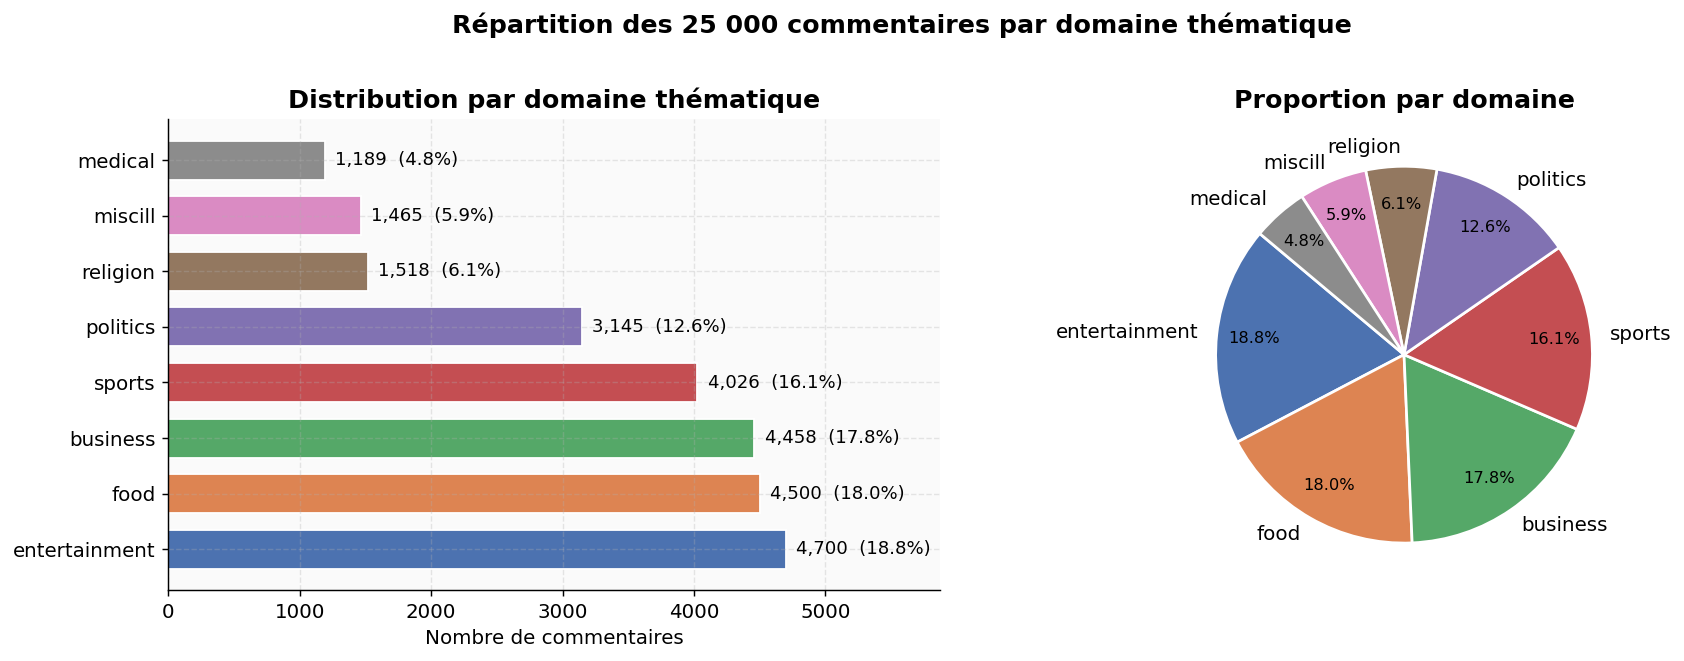


Domaine dominant : entertainment (4,700 textes, 18.8%)
Domaine minoritaire : medical (1,189 textes, 4.8%)
Ratio max/min : 4.0x


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Barres horizontales ───────────────────────────────────────────────
counts = df['domain'].value_counts()
colors = [PALETTE_DOMAIN.get(d, '#999') for d in counts.index]
bars = axes[0].barh(counts.index, counts.values, color=colors, edgecolor='white', height=0.7)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_width() + 80, bar.get_y() + bar.get_height()/2,
                 f'{val:,}  ({val/len(df)*100:.1f}%)',
                 va='center', fontsize=10)
axes[0].set_xlabel('Nombre de commentaires')
axes[0].set_title('Distribution par domaine thématique')
axes[0].set_xlim(0, counts.max() * 1.25)

# ── Camembert ────────────────────────────────────────────────────────
wedges, texts, autotexts = axes[1].pie(
    counts.values, labels=counts.index,
    colors=colors, autopct='%1.1f%%',
    startangle=140, pctdistance=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for autotext in autotexts:
    autotext.set_fontsize(9)
axes[1].set_title('Proportion par domaine')

plt.suptitle('Répartition des 25 000 commentaires par domaine thématique',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('01_distribution_domaines')
plt.show()
print(f'\nDomaine dominant : {counts.index[0]} ({counts.iloc[0]:,} textes, {counts.iloc[0]/len(df)*100:.1f}%)')
print(f'Domaine minoritaire : {counts.index[-1]} ({counts.iloc[-1]:,} textes, {counts.iloc[-1]/len(df)*100:.1f}%)')
print(f'Ratio max/min : {counts.iloc[0]/counts.iloc[-1]:.1f}x')

### 2.2 Déséquilibre des classes

Ce graphique montre le rapport entre chaque classe et la classe la plus fréquente, mettant en évidence le degré de déséquilibre. Le ratio est calculé comme le nombre de textes de la classe majoritaire divisé par le nombre de textes de chaque classe.

**But :** Quantifier précisément le déséquilibre pour décider de la stratégie d'équilibrage à adopter lors de l'entraînement.

  ✓ Exporté → data\reports\02_desequilibre_classes.png


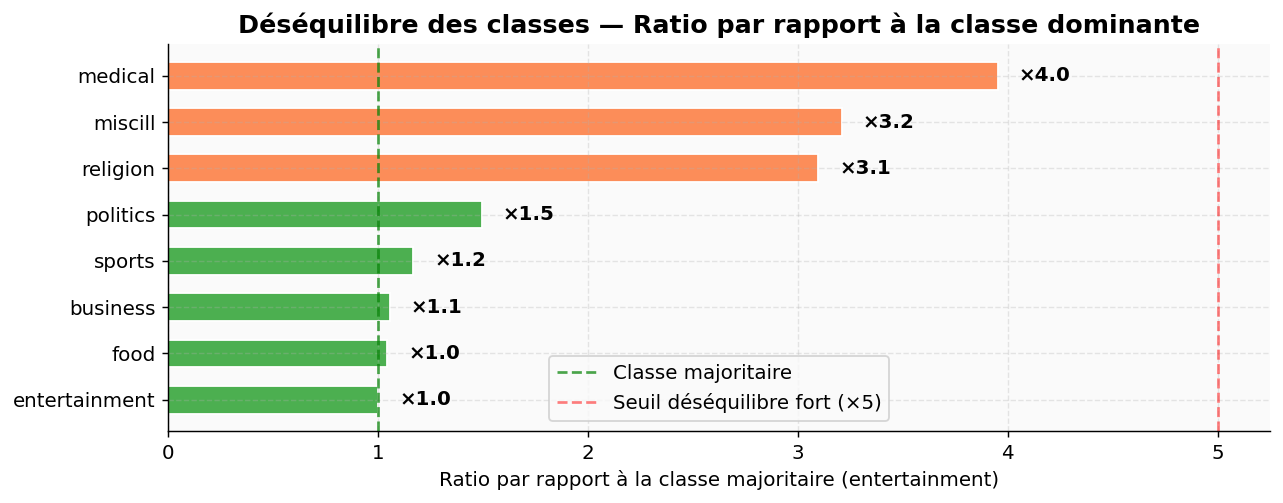

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
max_count = counts.max()
ratios = (max_count / counts).sort_values(ascending=True)
colors_ratio = ['#d73027' if r > 5 else '#fc8d59' if r > 2 else '#4CAF50' for r in ratios]
bars = ax.barh(ratios.index, ratios.values, color=colors_ratio, edgecolor='white', height=0.6)
for bar, val in zip(bars, ratios.values):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'×{val:.1f}', va='center', fontsize=11, fontweight='bold')
ax.axvline(x=1, color='green', linestyle='--', alpha=0.7, label='Classe majoritaire')
ax.axvline(x=5, color='red', linestyle='--', alpha=0.5, label='Seuil déséquilibre fort (×5)')
ax.set_xlabel("Ratio par rapport à la classe majoritaire (entertainment)")
ax.set_title("Déséquilibre des classes — Ratio par rapport à la classe dominante")
ax.legend()
plt.tight_layout()
save_fig('02_desequilibre_classes')
plt.show()

---
## Section 3 — Analyse des Types de Darija

### 3.1 Distribution globale des types

Le détecteur Darija classe chaque texte selon trois types : **darija_arabic** (texte en alphabet arabe), **darija_latin** (transcription en caractères latins / Arabizi) et **darija_mixed** (mélange des deux). Cette distribution est fondamentale pour comprendre la nature du corpus et choisir les stratégies de prétraitement appropriées (tokenisation, embeddings).

**Pourquoi c'est important ?** Un modèle NLP entraîné uniquement sur du Darija arabe sera moins performant sur le Darija latin, et vice versa.

  ✓ Exporté → data\reports\03_types_darija.png


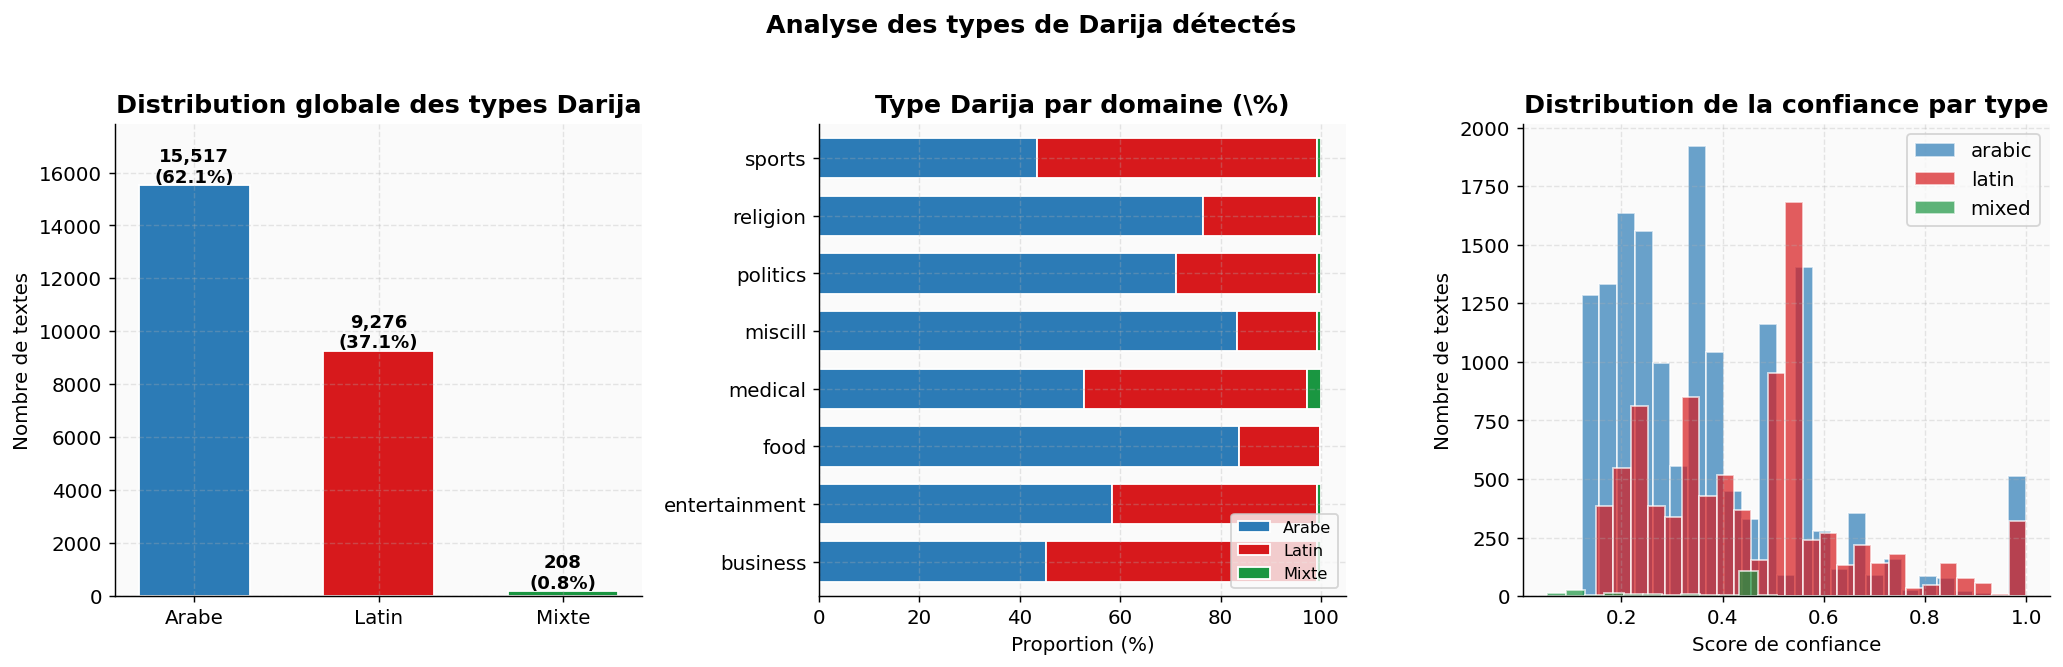


Résumé :
  darija_arabic        : 15,517  (62.1%)
  darija_latin         :  9,276  (37.1%)
  darija_mixed         :    208  (0.8%)


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Distribution globale ──────────────────────────────────────────────
type_counts = df['darija_type'].value_counts()
colors_type = [PALETTE_TYPE.get(t, '#999') for t in type_counts.index]
bars = axes[0].bar(type_counts.index, type_counts.values,
                   color=colors_type, edgecolor='white', width=0.6)
for bar, val in zip(bars, type_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{val:,}\n({val/len(df)*100:.1f}%)',
                 ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Distribution globale des types Darija')
axes[0].set_ylabel('Nombre de textes')
axes[0].set_ylim(0, type_counts.max() * 1.15)
axes[0].set_xticklabels(['Arabe', 'Latin', 'Mixte'])

# ── Par domaine (barres empilées) ─────────────────────────────────────
cross = pd.crosstab(df['domain'], df['darija_type'], normalize='index') * 100
cross = cross.reindex(columns=['darija_arabic','darija_latin','darija_mixed'])
cross.plot(kind='barh', stacked=True, ax=axes[1],
           color=[PALETTE_TYPE[c] for c in cross.columns],
           edgecolor='white', width=0.7)
axes[1].set_title('Type Darija par domaine (\%)')
axes[1].set_xlabel('Proportion (%)')
axes[1].legend(['Arabe','Latin','Mixte'], loc='lower right', fontsize=9)
axes[1].set_ylabel('')

# ── Confidence par type ───────────────────────────────────────────────
for i, (dtype, grp) in enumerate(df.groupby('darija_type')):
    axes[2].hist(grp['det_confidence'], bins=25, alpha=0.7,
                 color=PALETTE_TYPE.get(dtype, '#999'),
                 label=dtype.replace('darija_',''), edgecolor='white')
axes[2].set_title('Distribution de la confiance par type')
axes[2].set_xlabel('Score de confiance')
axes[2].set_ylabel('Nombre de textes')
axes[2].legend()

plt.suptitle('Analyse des types de Darija détectés', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('03_types_darija')
plt.show()

print('\nRésumé :')
for t, n in type_counts.items():
    print(f'  {t:<20} : {n:>6,}  ({n/len(df)*100:.1f}%)')

### 3.2 Score de confiance du détecteur

Le score de confiance indique à quel point le détecteur est certain de sa classification. Un score faible (< 0.2) indique un texte ambigu qui pourrait être mal classé. Ce graphique aide à identifier les seuils de fiabilité et les textes qui méritent une validation manuelle.

**But :** Déterminer si des textes à faible confiance doivent être réexaminés ou exclus du dataset d'entraînement.

  ✓ Exporté → data\reports\04_confiance_detecteur.png


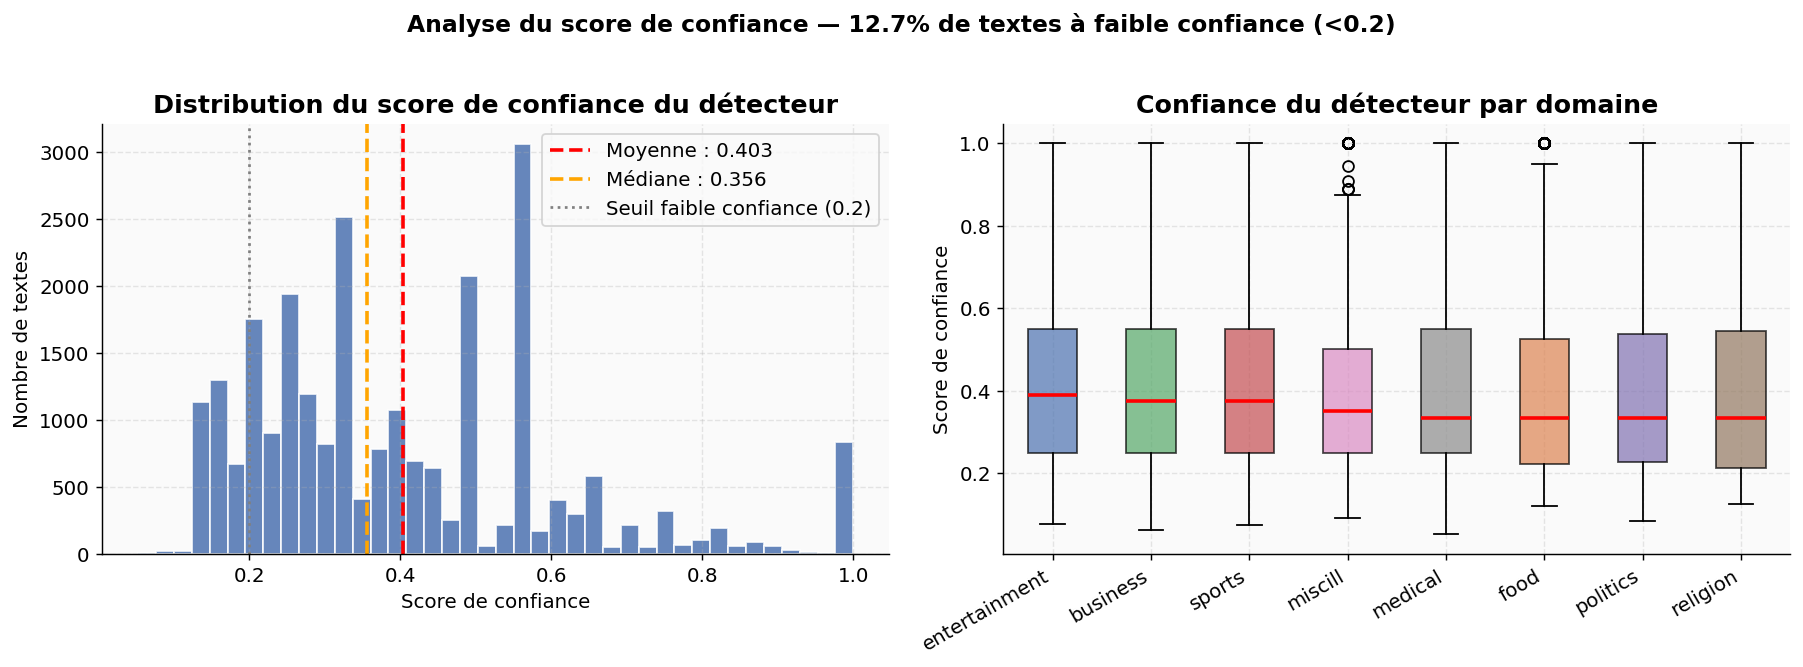

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Histogramme global confiance ─────────────────────────────────────
axes[0].hist(df['det_confidence'], bins=40, color='#4C72B0',
             edgecolor='white', alpha=0.85)
axes[0].axvline(df['det_confidence'].mean(), color='red', linestyle='--',
                linewidth=2, label=f'Moyenne : {df["det_confidence"].mean():.3f}')
axes[0].axvline(df['det_confidence'].median(), color='orange', linestyle='--',
                linewidth=2, label=f'Médiane : {df["det_confidence"].median():.3f}')
axes[0].axvline(0.2, color='gray', linestyle=':', linewidth=1.5,
                label='Seuil faible confiance (0.2)')
axes[0].set_xlabel('Score de confiance')
axes[0].set_ylabel('Nombre de textes')
axes[0].set_title('Distribution du score de confiance du détecteur')
axes[0].legend()

# ── Boxplot confiance par domaine ────────────────────────────────────
domain_order = df.groupby('domain')['det_confidence'].median().sort_values(ascending=False).index
data_by_domain = [df[df['domain'] == d]['det_confidence'].values for d in domain_order]
bp = axes[1].boxplot(data_by_domain, labels=domain_order, patch_artist=True,
                     medianprops={'color': 'red', 'linewidth': 2})
for patch, domain in zip(bp['boxes'], domain_order):
    patch.set_facecolor(PALETTE_DOMAIN.get(domain, '#999'))
    patch.set_alpha(0.7)
axes[1].set_xticklabels(domain_order, rotation=30, ha='right')
axes[1].set_ylabel('Score de confiance')
axes[1].set_title('Confiance du détecteur par domaine')

pct_faible = (df['det_confidence'] < 0.2).mean() * 100
plt.suptitle(f'Analyse du score de confiance — {pct_faible:.1f}% de textes à faible confiance (<0.2)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('04_confiance_detecteur')
plt.show()

---
## Section 4 — Analyse des Longueurs de Textes

### 4.1 Distribution du nombre de mots

La longueur des textes est une caractéristique fondamentale pour la modélisation NLP. Elle détermine la fenêtre de contexte nécessaire, le choix du modèle (BERT est limité à 512 tokens) et les performances attendues. Des textes très courts (1-3 mots) portent peu d'information thématique, tandis que les textes très longs sont rares et peuvent être des outliers.

**But :** Identifier la plage de longueurs typiques et détecter les outliers qui pourraient perturber l'entraînement.

  ✓ Exporté → data\reports\05_longueurs_textes.png


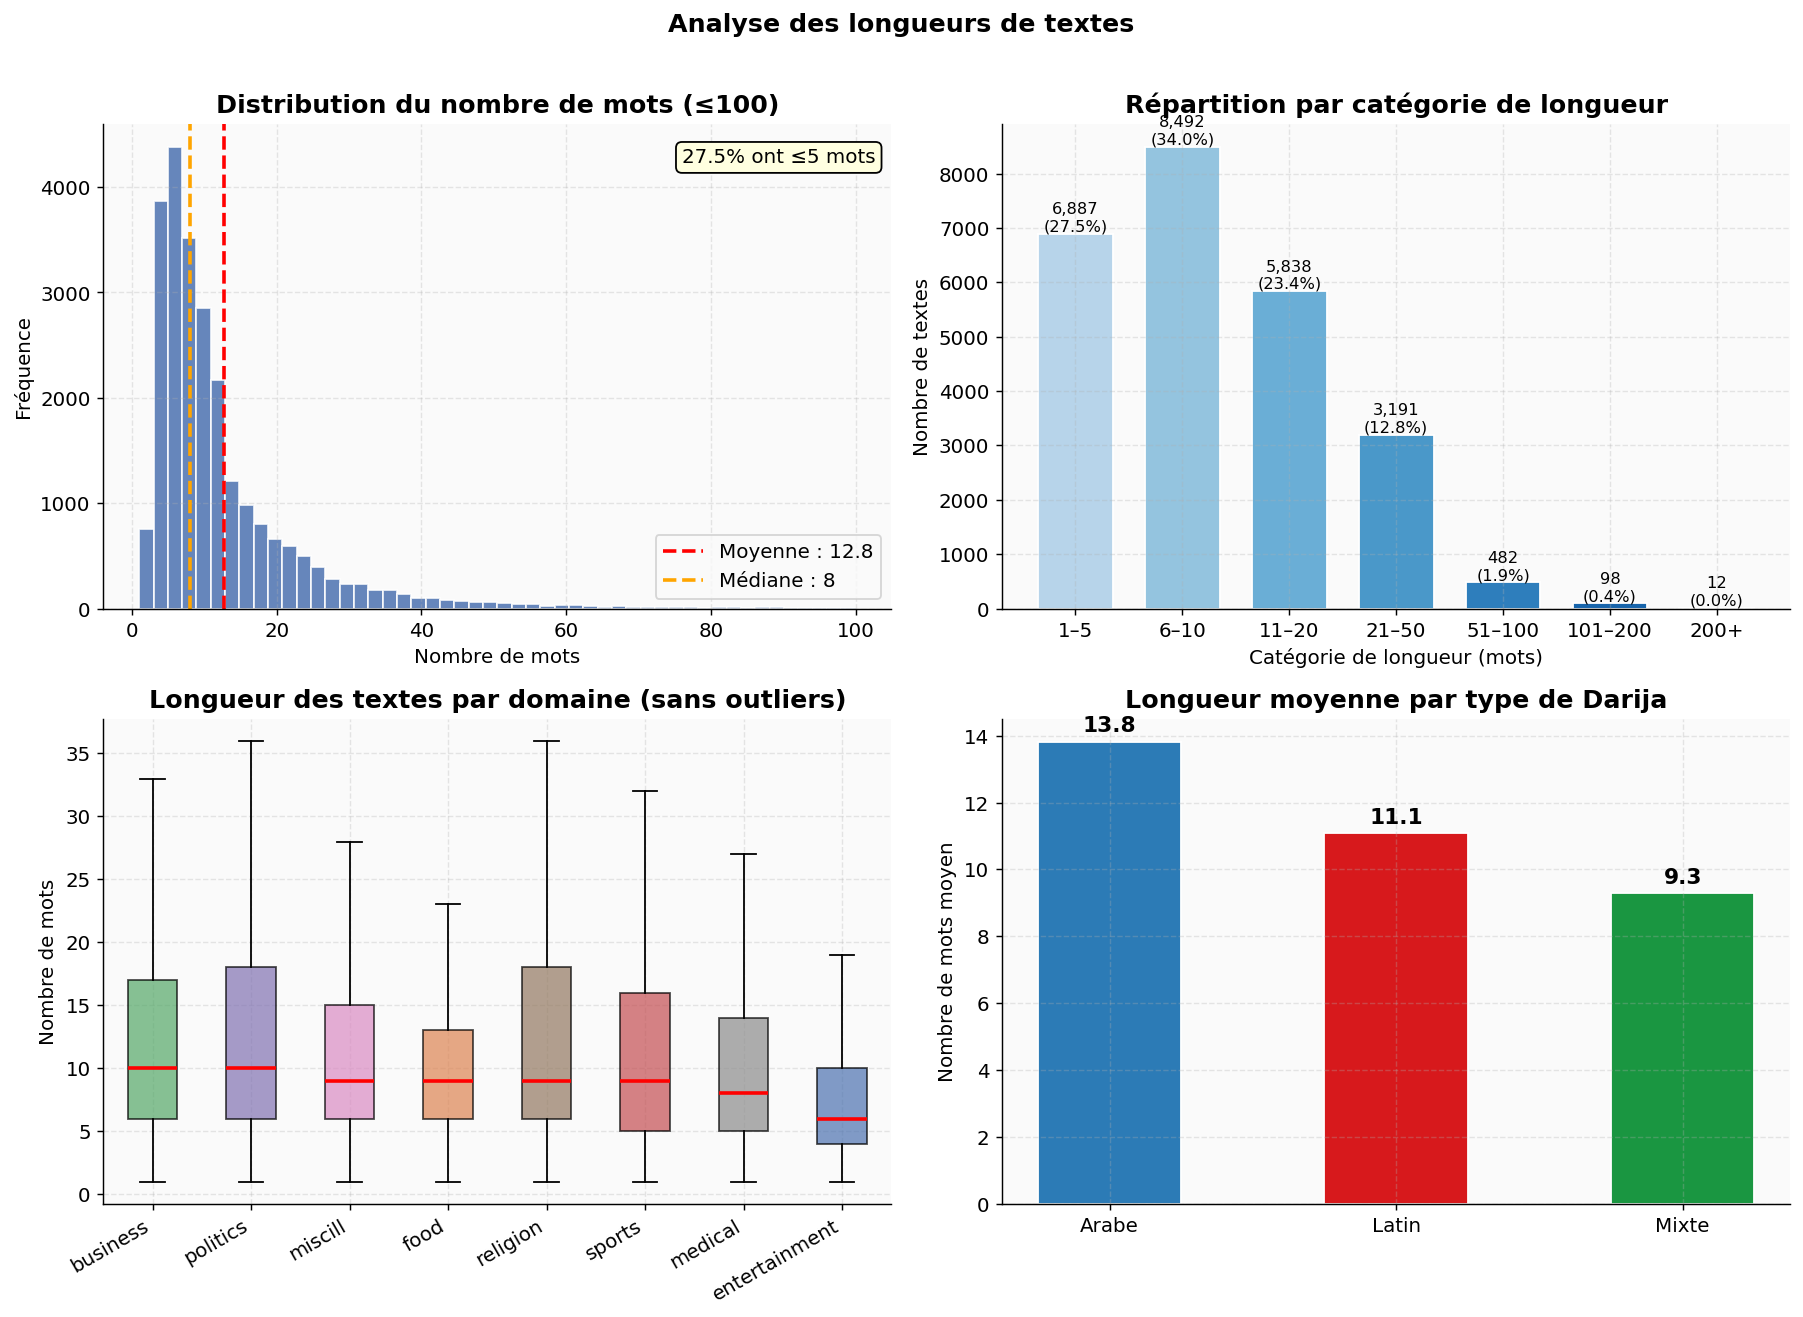

Statistiques n_words :
count    25001.000000
mean        12.761970
std         15.696181
min          1.000000
25%          5.000000
50%          8.000000
75%         14.000000
max        640.000000

Textes ≤ 5 mots  : 6,887 (27.5%)
Textes > 50 mots : 593 (2.4%)


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ── Histogramme n_words (tronqué à 100) ─────────────────────────────
df_trunc = df[df['n_words'] <= 100]
axes[0,0].hist(df_trunc['n_words'], bins=50, color='#4C72B0',
               edgecolor='white', alpha=0.85)
axes[0,0].axvline(df['n_words'].mean(), color='red', linestyle='--',
                  linewidth=2, label=f'Moyenne : {df["n_words"].mean():.1f}')
axes[0,0].axvline(df['n_words'].median(), color='orange', linestyle='--',
                  linewidth=2, label=f'Médiane : {df["n_words"].median():.0f}')
axes[0,0].set_xlabel('Nombre de mots')
axes[0,0].set_ylabel('Fréquence')
axes[0,0].set_title('Distribution du nombre de mots (≤100)')
axes[0,0].legend()
pct_courts = (df['n_words'] <= 5).mean()*100
axes[0,0].text(0.98, 0.95, f'{pct_courts:.1f}% ont ≤5 mots',
               transform=axes[0,0].transAxes, ha='right', va='top',
               bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow'))

# ── Catégories de longueur ────────────────────────────────────────────
bins   = [0, 5, 10, 20, 50, 100, 200, 600]
labels = ['1–5', '6–10', '11–20', '21–50', '51–100', '101–200', '200+']
df['len_cat'] = pd.cut(df['n_words'], bins=bins, labels=labels)
len_counts = df['len_cat'].value_counts().sort_index()
gradient = plt.cm.Blues(np.linspace(0.3, 0.9, len(len_counts)))
bars = axes[0,1].bar(len_counts.index, len_counts.values,
                     color=gradient, edgecolor='white', width=0.7)
for bar, val in zip(bars, len_counts.values):
    axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                   f'{val:,}\n({val/len(df)*100:.1f}%)',
                   ha='center', fontsize=9)
axes[0,1].set_xlabel('Catégorie de longueur (mots)')
axes[0,1].set_ylabel('Nombre de textes')
axes[0,1].set_title('Répartition par catégorie de longueur')

# ── Boxplot longueur par domaine ─────────────────────────────────────
domain_order2 = df.groupby('domain')['n_words'].median().sort_values(ascending=False).index
data2 = [df[df['domain']==d]['n_words'].clip(upper=80).values for d in domain_order2]
bp2 = axes[1,0].boxplot(data2, labels=domain_order2, patch_artist=True,
                         medianprops={'color':'red','linewidth':2},
                         showfliers=False)
for patch, domain in zip(bp2['boxes'], domain_order2):
    patch.set_facecolor(PALETTE_DOMAIN.get(domain, '#999'))
    patch.set_alpha(0.7)
axes[1,0].set_xticklabels(domain_order2, rotation=30, ha='right')
axes[1,0].set_ylabel('Nombre de mots')
axes[1,0].set_title('Longueur des textes par domaine (sans outliers)')

# ── Longueur moyenne par type Darija ─────────────────────────────────
mean_len = df.groupby('darija_type')['n_words'].mean().sort_values(ascending=False)
colors_t  = [PALETTE_TYPE.get(t,'#999') for t in mean_len.index]
bars3 = axes[1,1].bar(mean_len.index, mean_len.values,
                      color=colors_t, edgecolor='white', width=0.5)
for bar, val in zip(bars3, mean_len.values):
    axes[1,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                   f'{val:.1f}', ha='center', fontsize=12, fontweight='bold')
axes[1,1].set_ylabel('Nombre de mots moyen')
axes[1,1].set_title('Longueur moyenne par type de Darija')
axes[1,1].set_xticklabels(['Arabe','Latin','Mixte'])

plt.suptitle('Analyse des longueurs de textes', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('05_longueurs_textes')
plt.show()

print(f'Statistiques n_words :')
print(df['n_words'].describe().to_string())
print(f'\nTextes ≤ 5 mots  : {(df["n_words"]<=5).sum():,} ({(df["n_words"]<=5).mean()*100:.1f}%)')
print(f'Textes > 50 mots : {(df["n_words"]>50).sum():,} ({(df["n_words"]>50).mean()*100:.1f}%)')

---
## Section 5 — Analyse Temporelle

### 5.1 Évolution du volume de commentaires dans le temps

L'analyse temporelle révèle quand les données ont été produites et si le dataset couvre une période homogène ou présente des pics d'activité. Des pics anormaux peuvent indiquer des événements viraux ou des biais de collecte. La répartition temporelle affecte aussi la représentativité du langage (le Darija utilisé en 2015 peut différer de celui de 2025).

**But :** Vérifier la cohérence temporelle du dataset et identifier d'éventuels biais de collecte.

  ✓ Exporté → data\reports\06_analyse_temporelle.png


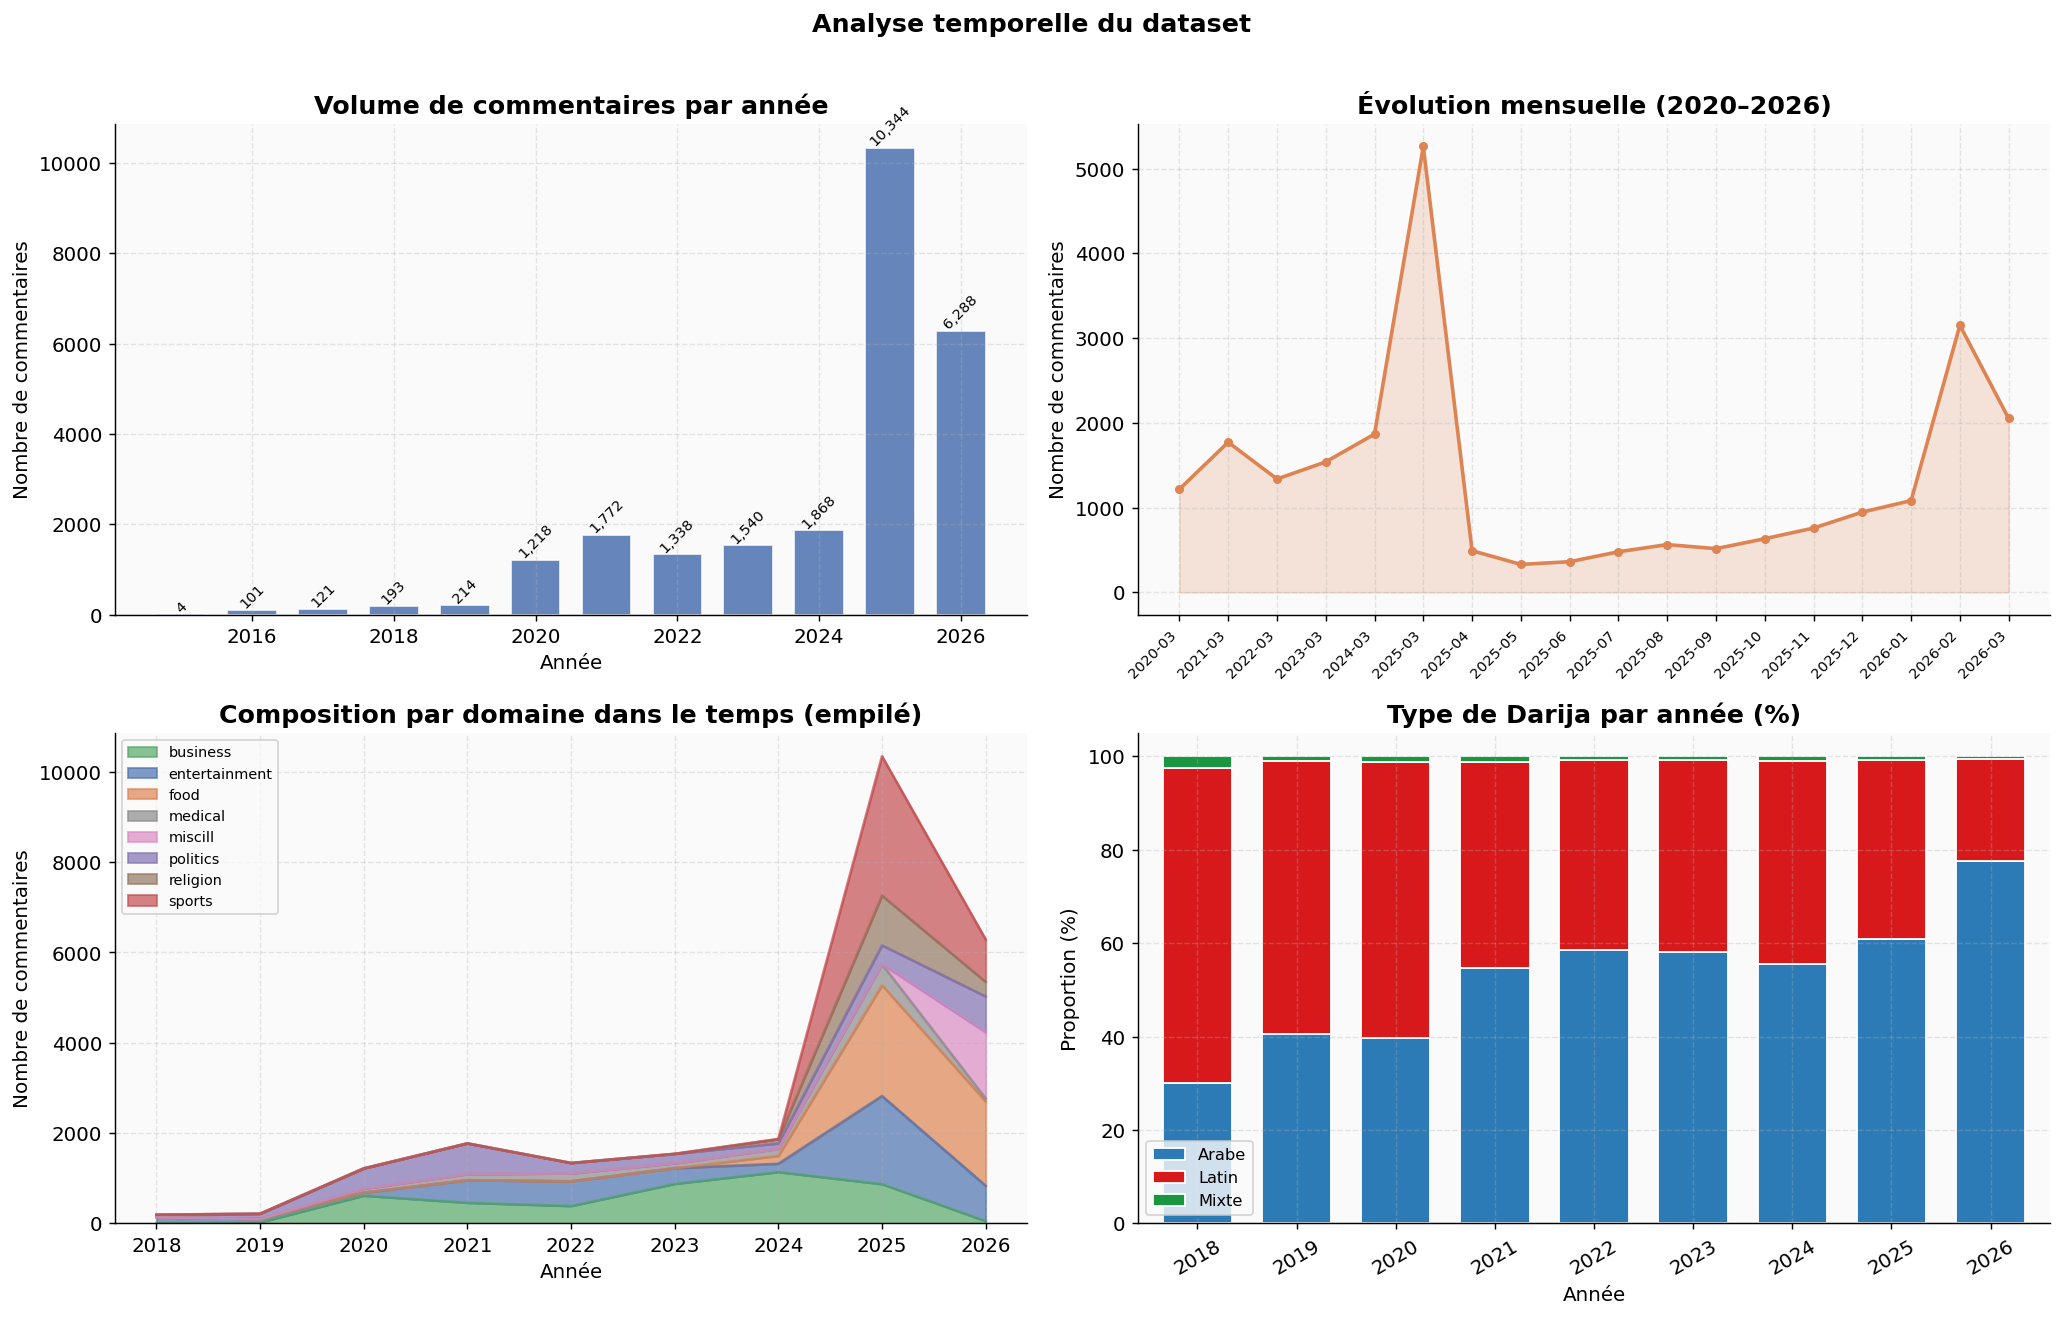

Période : 10/03/2015 → 09/03/2026
Année la plus représentée : 2025 (10,344 textes)


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# ── Volume par année ──────────────────────────────────────────────────
year_counts = df['annee'].value_counts().sort_index()
year_counts = year_counts[year_counts.index >= 2015]
axes[0,0].bar(year_counts.index, year_counts.values,
              color='#4C72B0', edgecolor='white', alpha=0.85, width=0.7)
axes[0,0].set_xlabel('Année')
axes[0,0].set_ylabel('Nombre de commentaires')
axes[0,0].set_title('Volume de commentaires par année')
for x, y in zip(year_counts.index, year_counts.values):
    axes[0,0].text(x, y + 50, f'{y:,}', ha='center', fontsize=8, rotation=45)

# ── Volume mensuel (2020 → 2026) ─────────────────────────────────────
monthly = df[df['annee'] >= 2020].groupby('mois').size()
monthly.index = monthly.index.astype(str)
step = max(1, len(monthly) // 15)
axes[0,1].plot(range(len(monthly)), monthly.values,
               color='#DD8452', linewidth=2, marker='o', markersize=4)
axes[0,1].fill_between(range(len(monthly)), monthly.values, alpha=0.2, color='#DD8452')
axes[0,1].set_xticks(range(0, len(monthly), step))
axes[0,1].set_xticklabels(list(monthly.index)[::step], rotation=45, ha='right', fontsize=8)
axes[0,1].set_ylabel('Nombre de commentaires')
axes[0,1].set_title('Évolution mensuelle (2020–2026)')

# ── Distribution par domaine dans le temps ────────────────────────────
pivot_year = df[df['annee'] >= 2018].groupby(['annee','domain']).size().unstack(fill_value=0)
pivot_year.plot(kind='area', stacked=True, ax=axes[1,0], alpha=0.7,
                color=[PALETTE_DOMAIN.get(c,'#999') for c in pivot_year.columns])
axes[1,0].set_xlabel('Année')
axes[1,0].set_ylabel('Nombre de commentaires')
axes[1,0].set_title('Composition par domaine dans le temps (empilé)')
axes[1,0].legend(fontsize=8, loc='upper left')

# ── Type Darija par année ─────────────────────────────────────────────
pivot_type = df[df['annee'] >= 2018].groupby(['annee','darija_type']).size().unstack(fill_value=0)
pivot_type_pct = pivot_type.div(pivot_type.sum(axis=1), axis=0) * 100
pivot_type_pct.plot(kind='bar', stacked=True, ax=axes[1,1],
                    color=[PALETTE_TYPE.get(c,'#999') for c in pivot_type_pct.columns],
                    edgecolor='white', width=0.7)
axes[1,1].set_xlabel('Année')
axes[1,1].set_ylabel('Proportion (%)')
axes[1,1].set_title('Type de Darija par année (%)')
axes[1,1].legend(['Arabe','Latin','Mixte'], fontsize=9)
axes[1,1].tick_params(axis='x', rotation=30)

plt.suptitle('Analyse temporelle du dataset', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('06_analyse_temporelle')
plt.show()

print(f'Période : {df["date"].min().strftime("%d/%m/%Y")} → {df["date"].max().strftime("%d/%m/%Y")}')
print(f'Année la plus représentée : {year_counts.idxmax()} ({year_counts.max():,} textes)')

---
## Section 6 — Analyse des Chaînes YouTube

### 6.1 Top chaînes par volume de commentaires

Comprendre quelles chaînes contribuent le plus au dataset est crucial pour évaluer la diversité des sources. Un dataset dominé par une ou deux chaînes introduit un biais de style et de vocabulaire. Si une seule chaîne représente 30% du dataset, ses particularités langagières seront surreprésentées dans le modèle.

**But :** Évaluer la diversité des sources et détecter les biais de surreprésentation.

  ✓ Exporté → data\reports\07_analyse_chaines.png


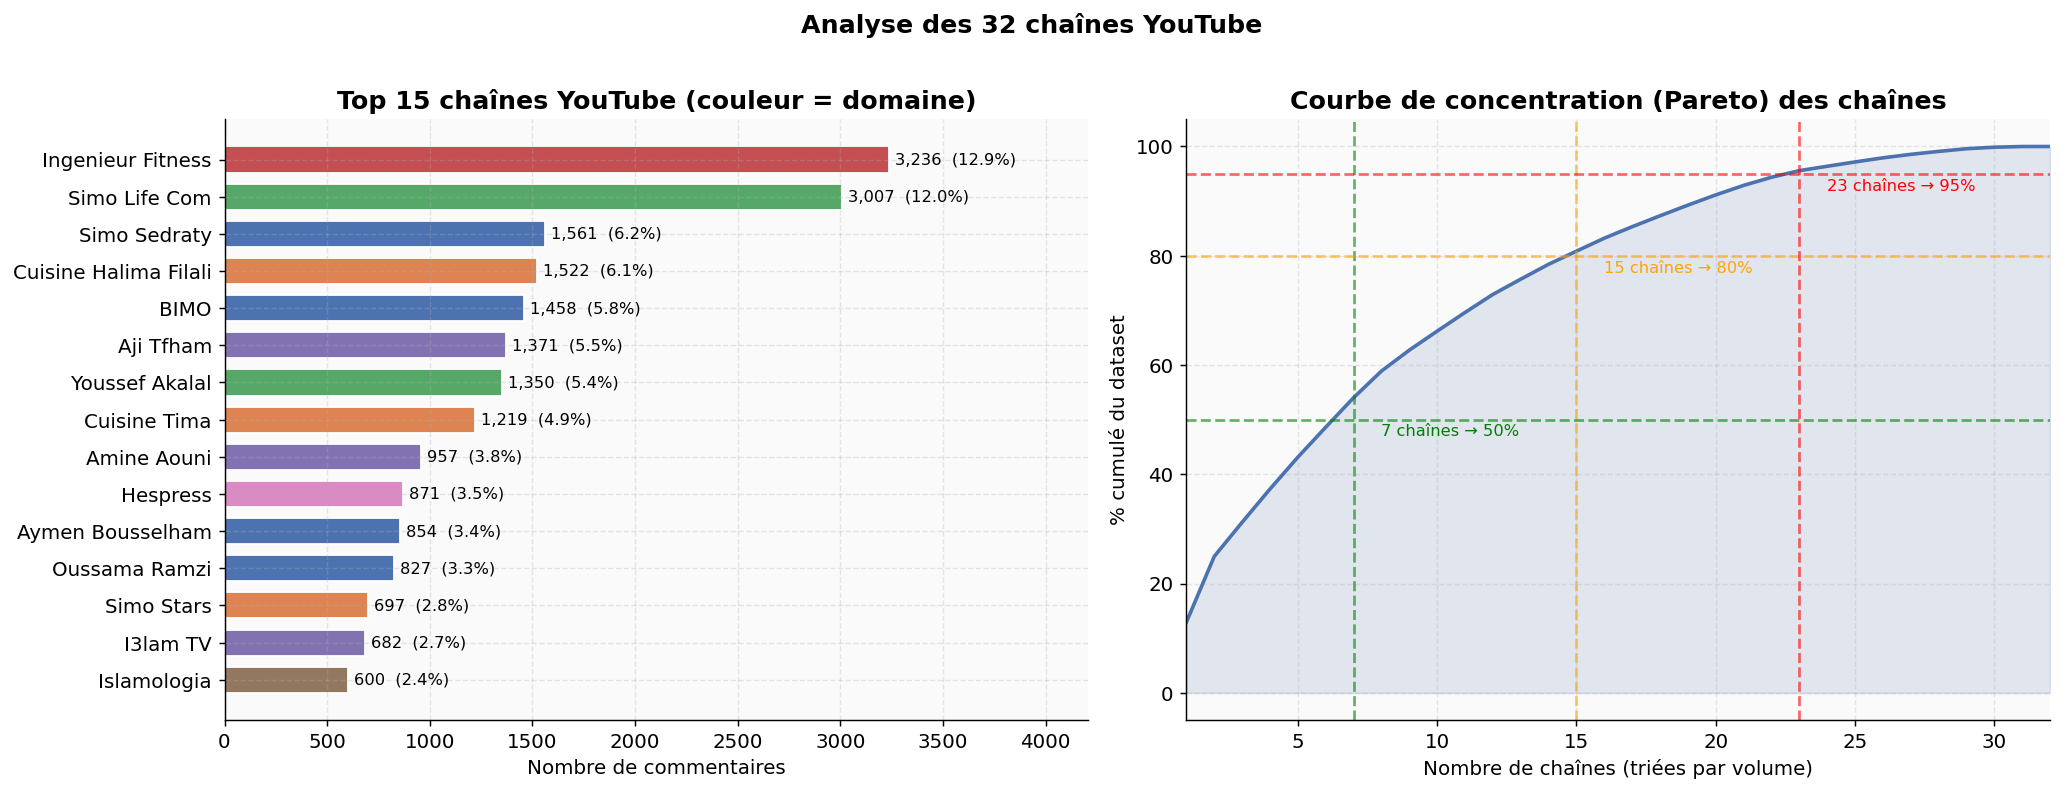

Nombre total de chaînes : 32
Top 3 chaînes : Ingenieur Fitness, Simo Life Com, Simo Sedraty
Part des top 3 chaînes : 31.2% du dataset


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Top 15 chaînes ────────────────────────────────────────────────────
top15 = df['channel_name'].value_counts().head(15)
colors_ch = [PALETTE_DOMAIN.get(
    df[df['channel_name']==ch]['domain'].mode()[0], '#999') for ch in top15.index]
bars = axes[0].barh(top15.index[::-1], top15.values[::-1],
                    color=colors_ch[::-1], edgecolor='white', height=0.7)
for bar, val in zip(bars, top15.values[::-1]):
    axes[0].text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
                 f'{val:,}  ({val/len(df)*100:.1f}%)',
                 va='center', fontsize=9)
axes[0].set_xlabel('Nombre de commentaires')
axes[0].set_title('Top 15 chaînes YouTube (couleur = domaine)')
axes[0].set_xlim(0, top15.max() * 1.3)

# ── Courbe de concentration (Pareto) ─────────────────────────────────
channel_counts = df['channel_name'].value_counts()
cumulative_pct = channel_counts.cumsum() / len(df) * 100
n_channels = range(1, len(channel_counts)+1)
axes[1].plot(n_channels, cumulative_pct.values, color='#4C72B0', linewidth=2)
axes[1].fill_between(n_channels, cumulative_pct.values, alpha=0.15, color='#4C72B0')
# Marquer les seuils 50%, 80%, 95%
for pct_target, color in [(50,'green'),(80,'orange'),(95,'red')]:
    idx = next((i for i, v in enumerate(cumulative_pct.values) if v >= pct_target), None)
    if idx is not None:
        axes[1].axhline(pct_target, color=color, linestyle='--', alpha=0.6)
        axes[1].axvline(idx+1, color=color, linestyle='--', alpha=0.6)
        axes[1].text(idx+2, pct_target-3, f'{idx+1} chaînes → {pct_target}%',
                     fontsize=9, color=color)
axes[1].set_xlabel('Nombre de chaînes (triées par volume)')
axes[1].set_ylabel('% cumulé du dataset')
axes[1].set_title('Courbe de concentration (Pareto) des chaînes')
axes[1].set_xlim(1, min(100, len(channel_counts)))

plt.suptitle(f'Analyse des {df["channel_name"].nunique()} chaînes YouTube',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('07_analyse_chaines')
plt.show()

print(f'Nombre total de chaînes : {df["channel_name"].nunique()}')
print(f'Top 3 chaînes : {", ".join(top15.head(3).index.tolist())}')
top3_pct = top15.head(3).sum() / len(df) * 100
print(f'Part des top 3 chaînes : {top3_pct:.1f}% du dataset')

---
## Section 7 — Analyse Linguistique : Scripts et Code-Switching

### 7.1 Distribution des scripts d'écriture

Cette analyse distingue les textes écrits en alphabet arabe, en alphabet latin (Darija transcrit), et les textes mixtes. Le script utilisé conditionne directement le choix des outils de tokenisation, des embeddings et des modèles de langue à utiliser.

**But :** Comprendre la composition scripturale du dataset pour guider les choix architecturaux du modèle NLP.

  ✓ Exporté → data\reports\08_analyse_linguistique.png


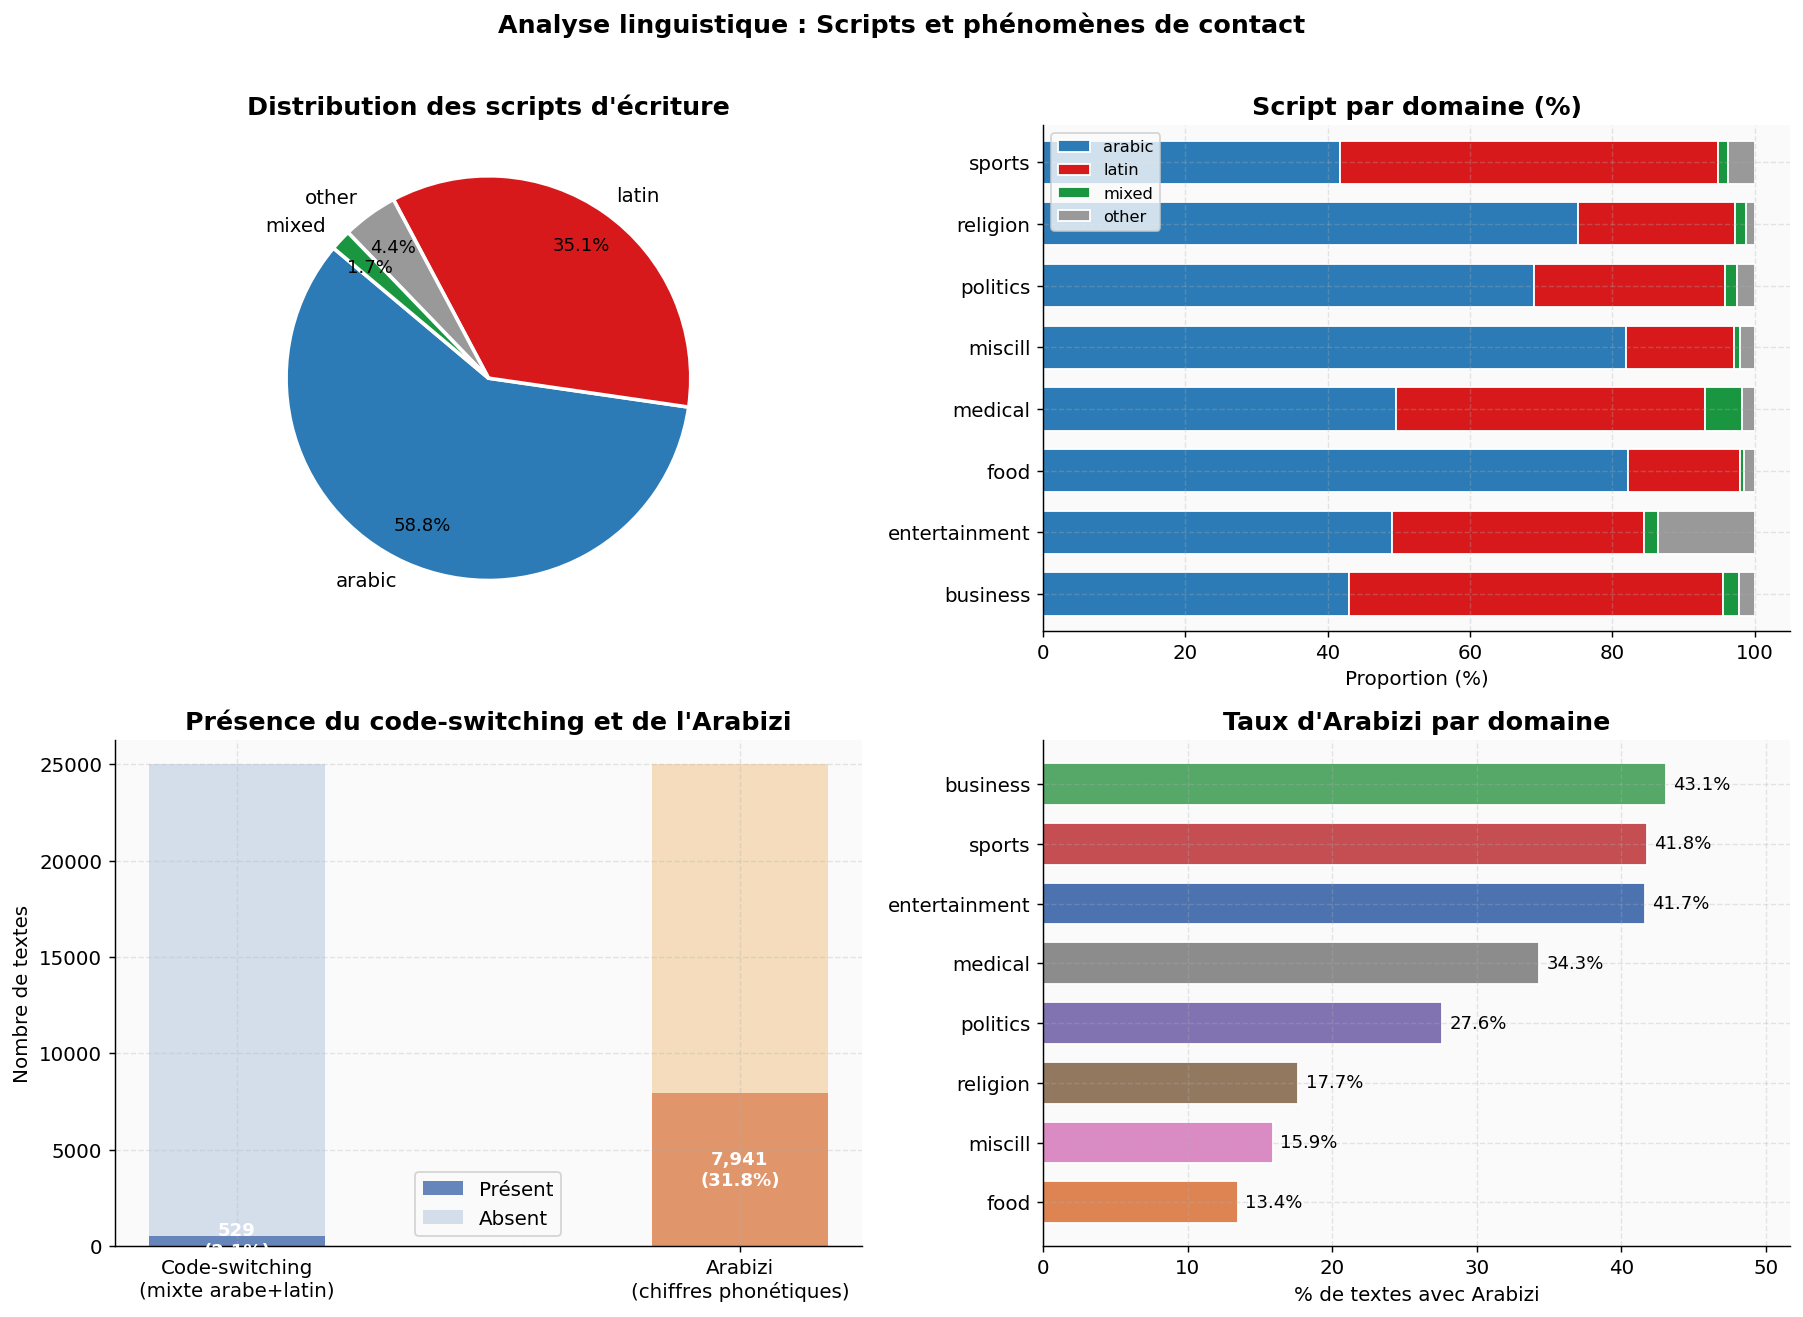

Code-switching : 529 textes (2.1%)
Arabizi        : 7,941 textes (31.8%)


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ── Distribution scripts ──────────────────────────────────────────────
script_counts = df['script'].value_counts()

sc_colors = {
    'arabic': '#2C7BB6',
    'latin': '#D7191C',
    'mixed': '#1A9641',
    'other': '#999999'
}

colors_sc = [sc_colors.get(s, '#999') for s in script_counts.index]

wedges, texts, autotexts = axes[0,0].pie(
    script_counts.values,
    labels=script_counts.index,
    colors=colors_sc,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor':'white','linewidth':2},
    pctdistance=0.8
)

for at in autotexts:
    at.set_fontsize(10)

axes[0,0].set_title("Distribution des scripts d'écriture")


# ── Script par domaine ────────────────────────────────────────────────
cross_sc = pd.crosstab(df['domain'], df['script'], normalize='index') * 100

cross_sc = cross_sc.reindex(
    columns=['arabic','latin','mixed','other'],
    fill_value=0
)

cross_sc.plot(
    kind='barh',
    stacked=True,
    ax=axes[0,1],
    color=[sc_colors.get(c,'#999') for c in cross_sc.columns],
    edgecolor='white',
    width=0.7
)

axes[0,1].set_title("Script par domaine (%)")
axes[0,1].set_xlabel("Proportion (%)")
axes[0,1].legend(fontsize=9)
axes[0,1].set_ylabel("")


# ── Code-switching et Arabizi ────────────────────────────────────────
features = ['has_codeswitching', 'has_arabizi']

labels_feat = [
    "Code-switching\n(mixte arabe+latin)",
    "Arabizi\n(chiffres phonétiques)"
]

totals = [df[f].sum() for f in features]
no_totals = [len(df) - t for t in totals]

x = np.arange(len(features))
width = 0.35

axes[1,0].bar(
    x,
    totals,
    width,
    label='Présent',
    color=['#4C72B0','#DD8452'],
    alpha=0.85
)

axes[1,0].bar(
    x,
    no_totals,
    width,
    bottom=totals,
    label='Absent',
    color=['#B0C4DE','#F0C080'],
    alpha=0.5
)

axes[1,0].set_xticks(x)
axes[1,0].set_xticklabels(labels_feat)

axes[1,0].set_ylabel("Nombre de textes")
axes[1,0].set_title("Présence du code-switching et de l'Arabizi")
axes[1,0].legend()

for xi, (t, tot) in enumerate(zip(totals, [len(df)]*2)):
    axes[1,0].text(
        xi,
        t/2,
        f'{t:,}\n({t/tot*100:.1f}%)',
        ha='center',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='white'
    )


# ── Arabizi par domaine ───────────────────────────────────────────────
arabizi_rate = (
    df.groupby('domain')['has_arabizi']
    .mean()
    .sort_values(ascending=True) * 100
)

colors_dom = [PALETTE_DOMAIN.get(d, '#999') for d in arabizi_rate.index]

bars = axes[1,1].barh(
    arabizi_rate.index,
    arabizi_rate.values,
    color=colors_dom,
    edgecolor='white',
    height=0.7
)

for bar, val in zip(bars, arabizi_rate.values):
    axes[1,1].text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height()/2,
        f'{val:.1f}%',
        va='center',
        fontsize=10
    )

axes[1,1].set_xlabel("% de textes avec Arabizi")
axes[1,1].set_title("Taux d'Arabizi par domaine")

axes[1,1].set_xlim(0, arabizi_rate.max() * 1.2)


# ── Titre global ──────────────────────────────────────────────────────
plt.suptitle(
    "Analyse linguistique : Scripts et phénomènes de contact",
    fontsize=14,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()

save_fig("08_analyse_linguistique")

plt.show()


# ── Statistiques finales ──────────────────────────────────────────────
print(
    f'Code-switching : {df["has_codeswitching"].sum():,} textes '
    f'({df["has_codeswitching"].mean()*100:.1f}%)'
)

print(
    f'Arabizi        : {df["has_arabizi"].sum():,} textes '
    f'({df["has_arabizi"].mean()*100:.1f}%)'
)

---
## Section 8 — Analyse des Scores du Détecteur

### 8.1 Distribution des scores linguistiques

Le détecteur Darija calcule trois scores pour chaque texte : `darija_lat_score` (proportion de mots Darija latin), `darija_ara_score` (proportion de mots Darija arabe) et `msa_score` (proportion de marqueurs MSA). Ces scores permettent de mesurer la "pureté" linguistique de chaque texte et d'identifier les cas limites.

**But :** Comprendre la distribution des scores pour calibrer les seuils du détecteur et identifier les textes qui méritent une attention particulière lors de l'annotation.

  ✓ Exporté → data\reports\09_scores_detecteur.png


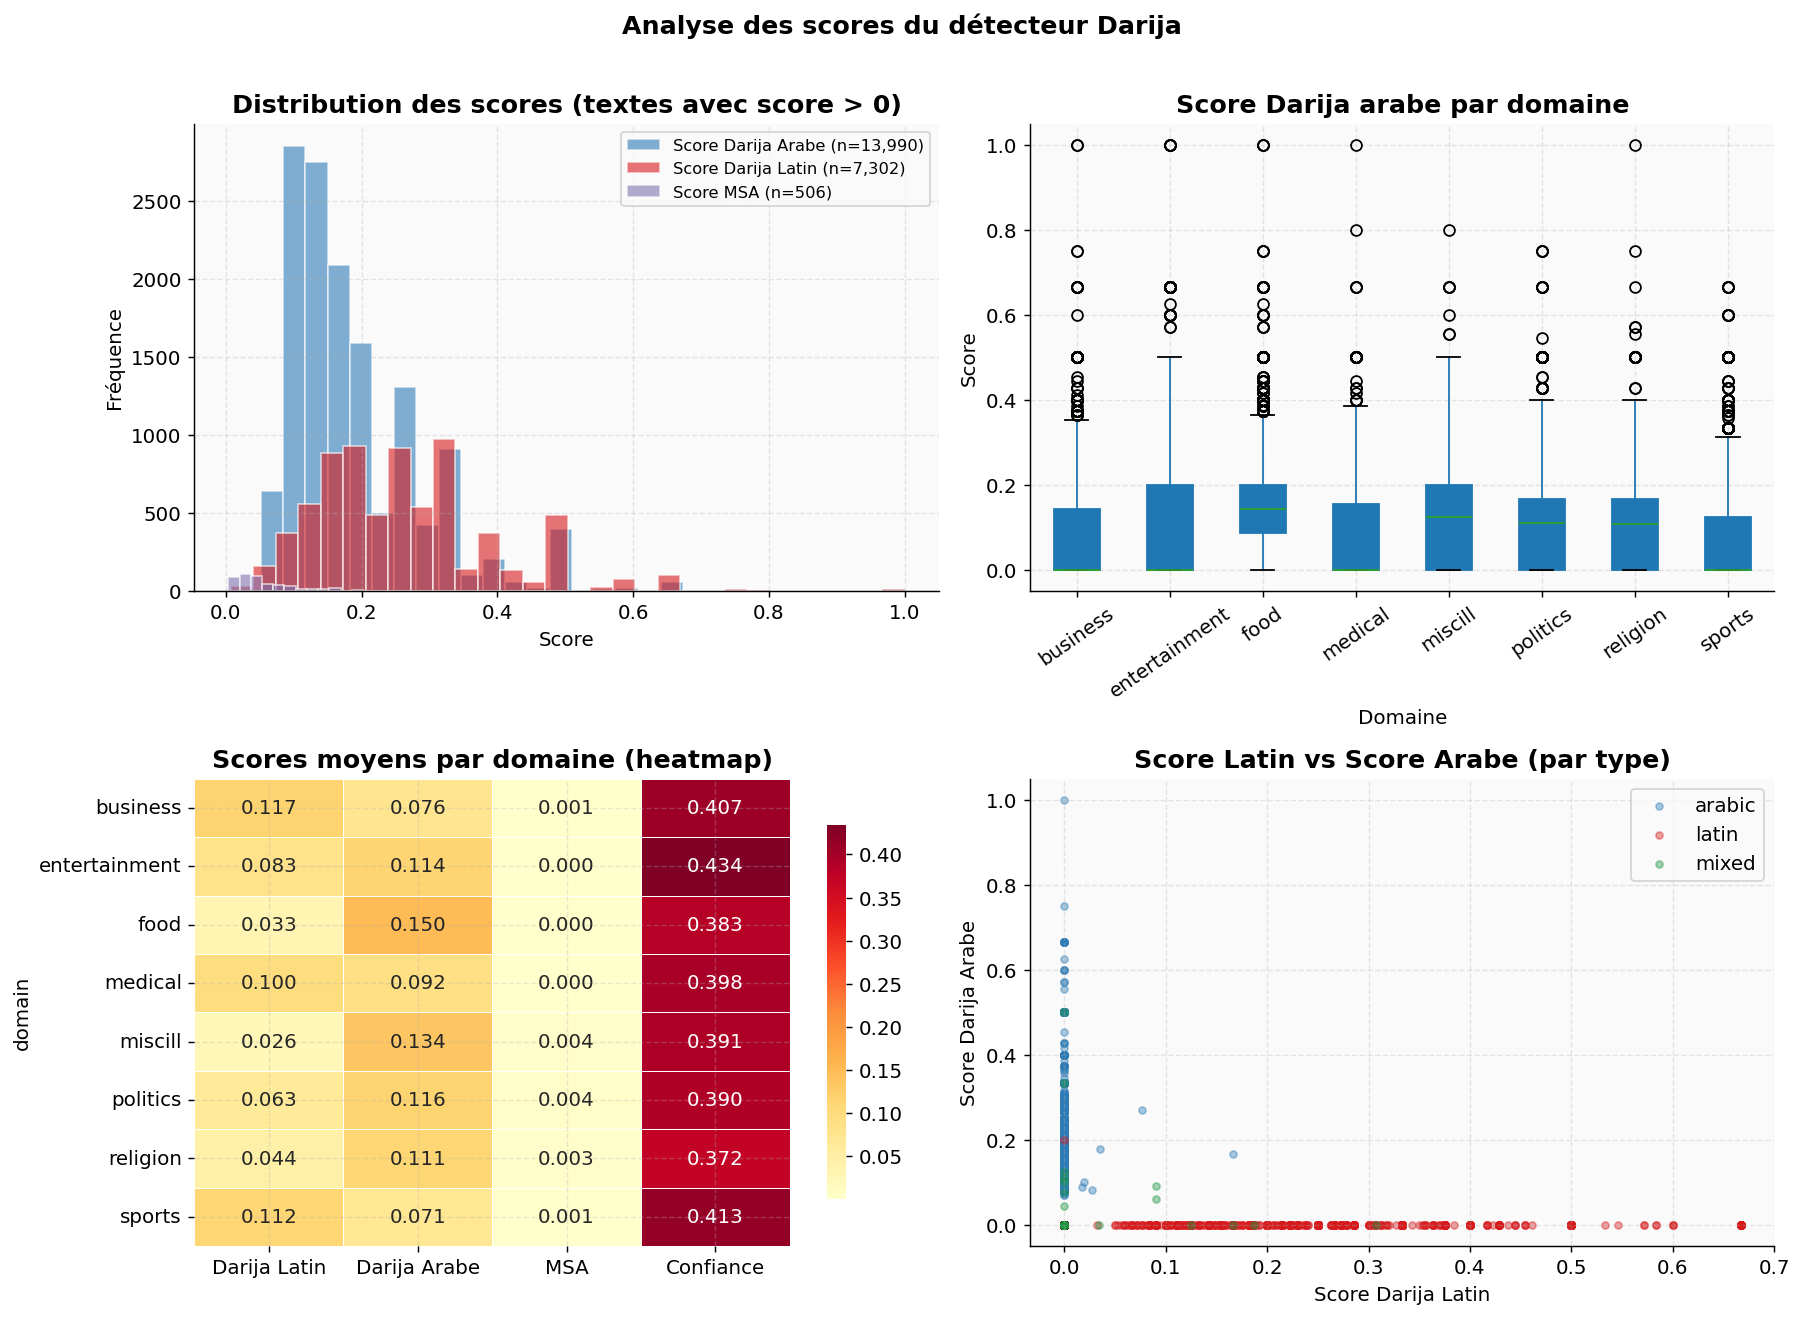

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ── Distribution des 3 scores ─────────────────────────────────────────
scores_info = [
    ('darija_ara_score', '#2C7BB6', 'Score Darija Arabe'),
    ('darija_lat_score', '#D7191C', 'Score Darija Latin'),
    ('msa_score',        '#8172B2', 'Score MSA'),
]
for col, color, label in scores_info:
    data = df[df[col] > 0][col]
    axes[0,0].hist(data, bins=30, alpha=0.6, color=color, label=f'{label} (n={len(data):,})', edgecolor='white')
axes[0,0].set_xlabel('Score')
axes[0,0].set_ylabel('Fréquence')
axes[0,0].set_title('Distribution des scores (textes avec score > 0)')
axes[0,0].legend(fontsize=9)

# ── Score Darija arabe par domaine ────────────────────────────────────
df.boxplot(column='darija_ara_score', by='domain', ax=axes[0,1],
           patch_artist=True)
axes[0,1].set_title('Score Darija arabe par domaine')
axes[0,1].set_xlabel('Domaine')
axes[0,1].set_ylabel('Score')
axes[0,1].tick_params(axis='x', rotation=35)
plt.sca(axes[0,1])
plt.title('Score Darija arabe par domaine')

# ── Heatmap scores moyens par domaine ────────────────────────────────
score_cols = ['darija_lat_score','darija_ara_score','msa_score','det_confidence']
score_labels = ['Darija Latin','Darija Arabe','MSA','Confiance']
heat_data = df.groupby('domain')[score_cols].mean()
heat_data.columns = score_labels
sns.heatmap(heat_data, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[1,0], cbar_kws={'shrink':0.8})
axes[1,0].set_title('Scores moyens par domaine (heatmap)')
axes[1,0].set_xlabel('')

# ── Scatter darija_ara vs darija_lat ──────────────────────────────────
sample = df.sample(min(3000, len(df)), random_state=42)
for dtype, grp in sample.groupby('darija_type'):
    axes[1,1].scatter(grp['darija_lat_score'], grp['darija_ara_score'],
                      alpha=0.4, s=15,
                      color=PALETTE_TYPE.get(dtype,'#999'),
                      label=dtype.replace('darija_',''))
axes[1,1].set_xlabel('Score Darija Latin')
axes[1,1].set_ylabel('Score Darija Arabe')
axes[1,1].set_title('Score Latin vs Score Arabe (par type)')
axes[1,1].legend()

plt.suptitle('Analyse des scores du détecteur Darija', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('09_scores_detecteur')
plt.show()

---
## Section 9 — Analyse des Mots Fréquents

### 9.1 Mots les plus fréquents par type de Darija

L'analyse de la fréquence des mots permet de comprendre le vocabulaire dominant dans chaque sous-corpus. Elle révèle les expressions idiomatiques, les formules récurrentes et les thèmes de discussion principaux. Cette analyse guide également l'enrichissement des lexiques du détecteur.

**But :** Identifier le vocabulaire caractéristique de chaque type de Darija et de chaque domaine, et vérifier que le dataset contient bien des mots Darija authentiques.

  ✓ Exporté → data\reports\10_mots_frequents_types.png


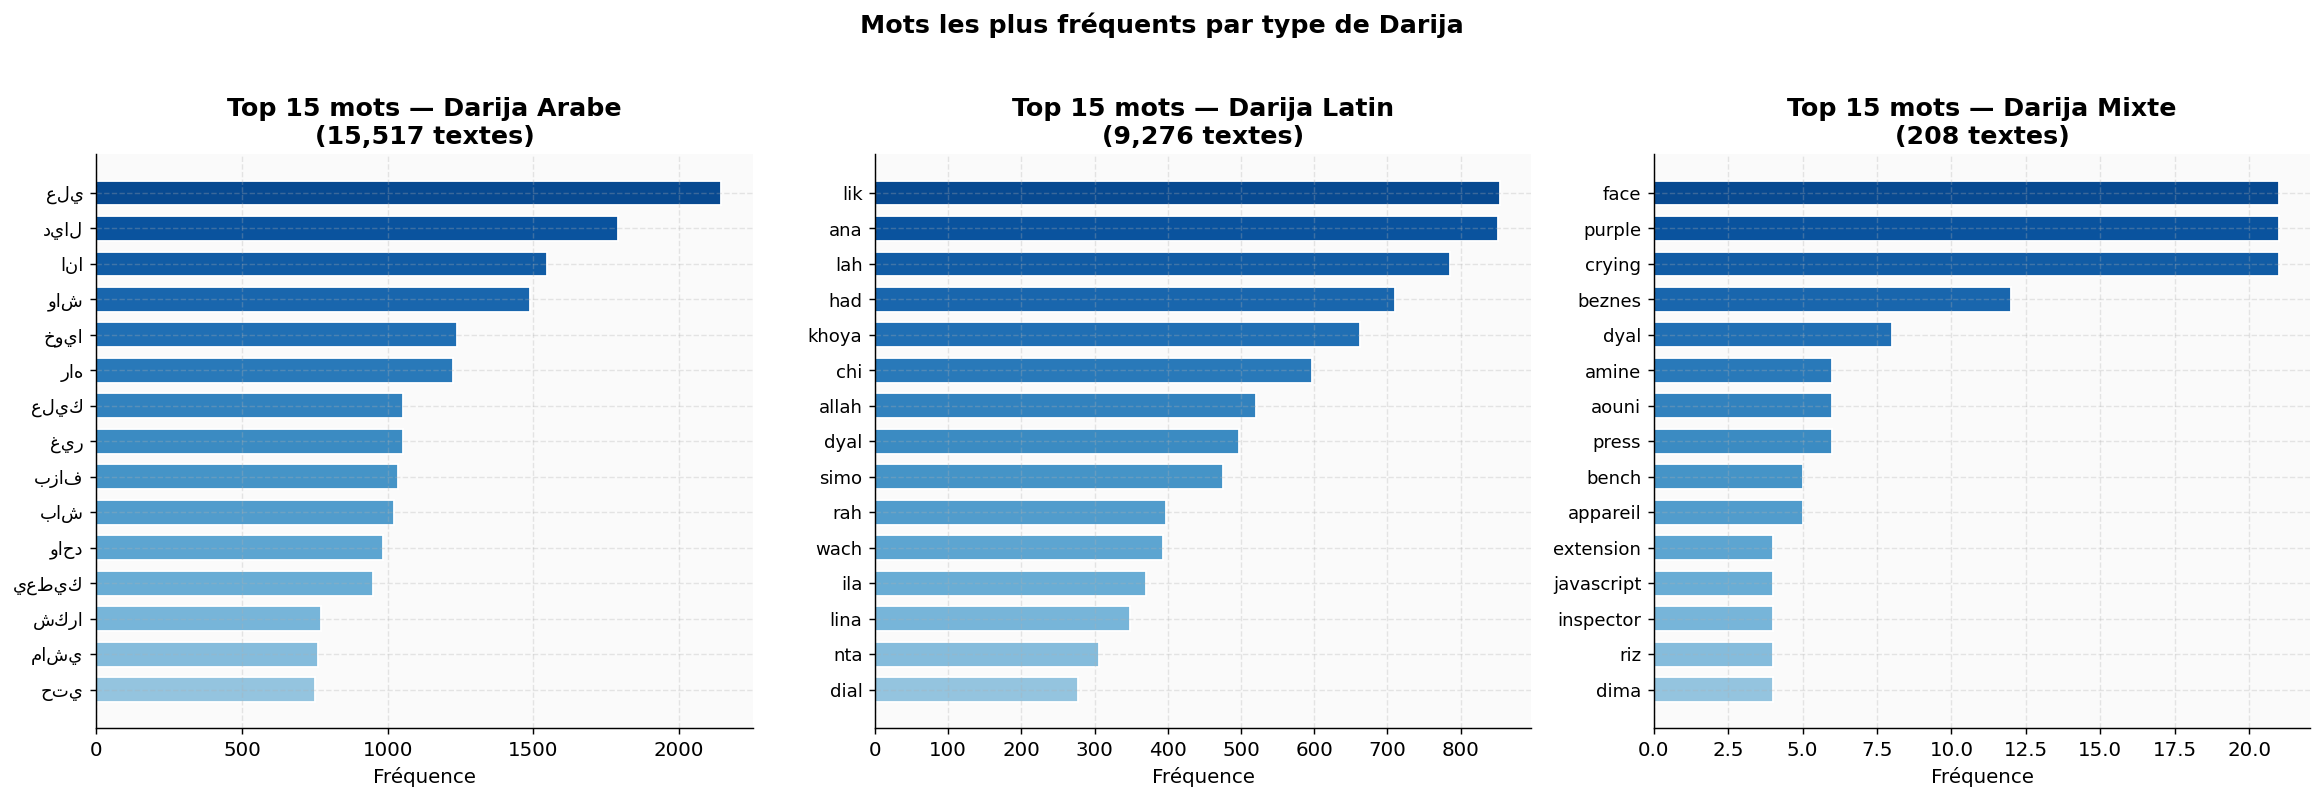

In [22]:
import re

def get_words(texts, arabic=True):
    """Extrait les mots d'une série de textes."""
    all_words = []
    for text in texts:
        if arabic:
            words = re.findall(r'[\u0600-\u06FF]{3,}', str(text))
        else:
            words = re.findall(r'[a-zA-Z]{3,}', str(text).lower())
        all_words.extend(words)
    return Counter(all_words)

# Stopwords arabes/latins à exclure
AR_STOP = {'الله','من','في','على','هاد','هذا','هذه','مع','لا','عن','ان','أن',
           'كان','كانت','هو','هي','وفي','ومن','على','لي','بالله','الذي'}
LAT_STOP = {'the','and','for','you','that','this','avec','pour','les','des',
            'une','que','qui','pas','elle','ils','nous','votre','notre'}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (dtype, label) in zip(axes, [
    ('darija_arabic','Darija Arabe'),
    ('darija_latin', 'Darija Latin'),
    ('darija_mixed', 'Darija Mixte')
]):
    subset = df[df['darija_type'] == dtype]['text_normalized']
    if dtype == 'darija_arabic':
        wc = get_words(subset, arabic=True)
        wc = Counter({w: c for w, c in wc.items() if w not in AR_STOP})
    else:
        wc = get_words(subset, arabic=False)
        wc = Counter({w: c for w, c in wc.items() if w not in LAT_STOP})
    
    top_words = wc.most_common(15)
    if not top_words:
        ax.text(0.5, 0.5, 'Pas de données', ha='center', transform=ax.transAxes)
        continue
    words_list, counts_list = zip(*top_words)
    gradient = plt.cm.Blues(np.linspace(0.4, 0.9, len(words_list)))
    bars = ax.barh(range(len(words_list)), counts_list[::-1],
                   color=gradient, edgecolor='white', height=0.7)
    ax.set_yticks(range(len(words_list)))
    ax.set_yticklabels(list(words_list[::-1]), fontsize=10)
    ax.set_xlabel('Fréquence')
    ax.set_title(f'Top 15 mots — {label}\n({len(subset):,} textes)', fontweight='bold')

plt.suptitle('Mots les plus fréquents par type de Darija', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('10_mots_frequents_types')
plt.show()

### 9.2 Mots les plus fréquents par domaine

Complémentairement à l'analyse précédente, cette visualisation montre le vocabulaire caractéristique de chaque domaine thématique. Elle permet de vérifier que le dataset contient bien des commentaires diversifiés et representatifs de chaque domaine, et d'identifier d'éventuelles contaminations entre domaines.

**But :** Valider que les domaines sont linguistiquement distincts et que le modèle pourra les discriminer.

  ✓ Exporté → data\reports\11_mots_par_domaine.png


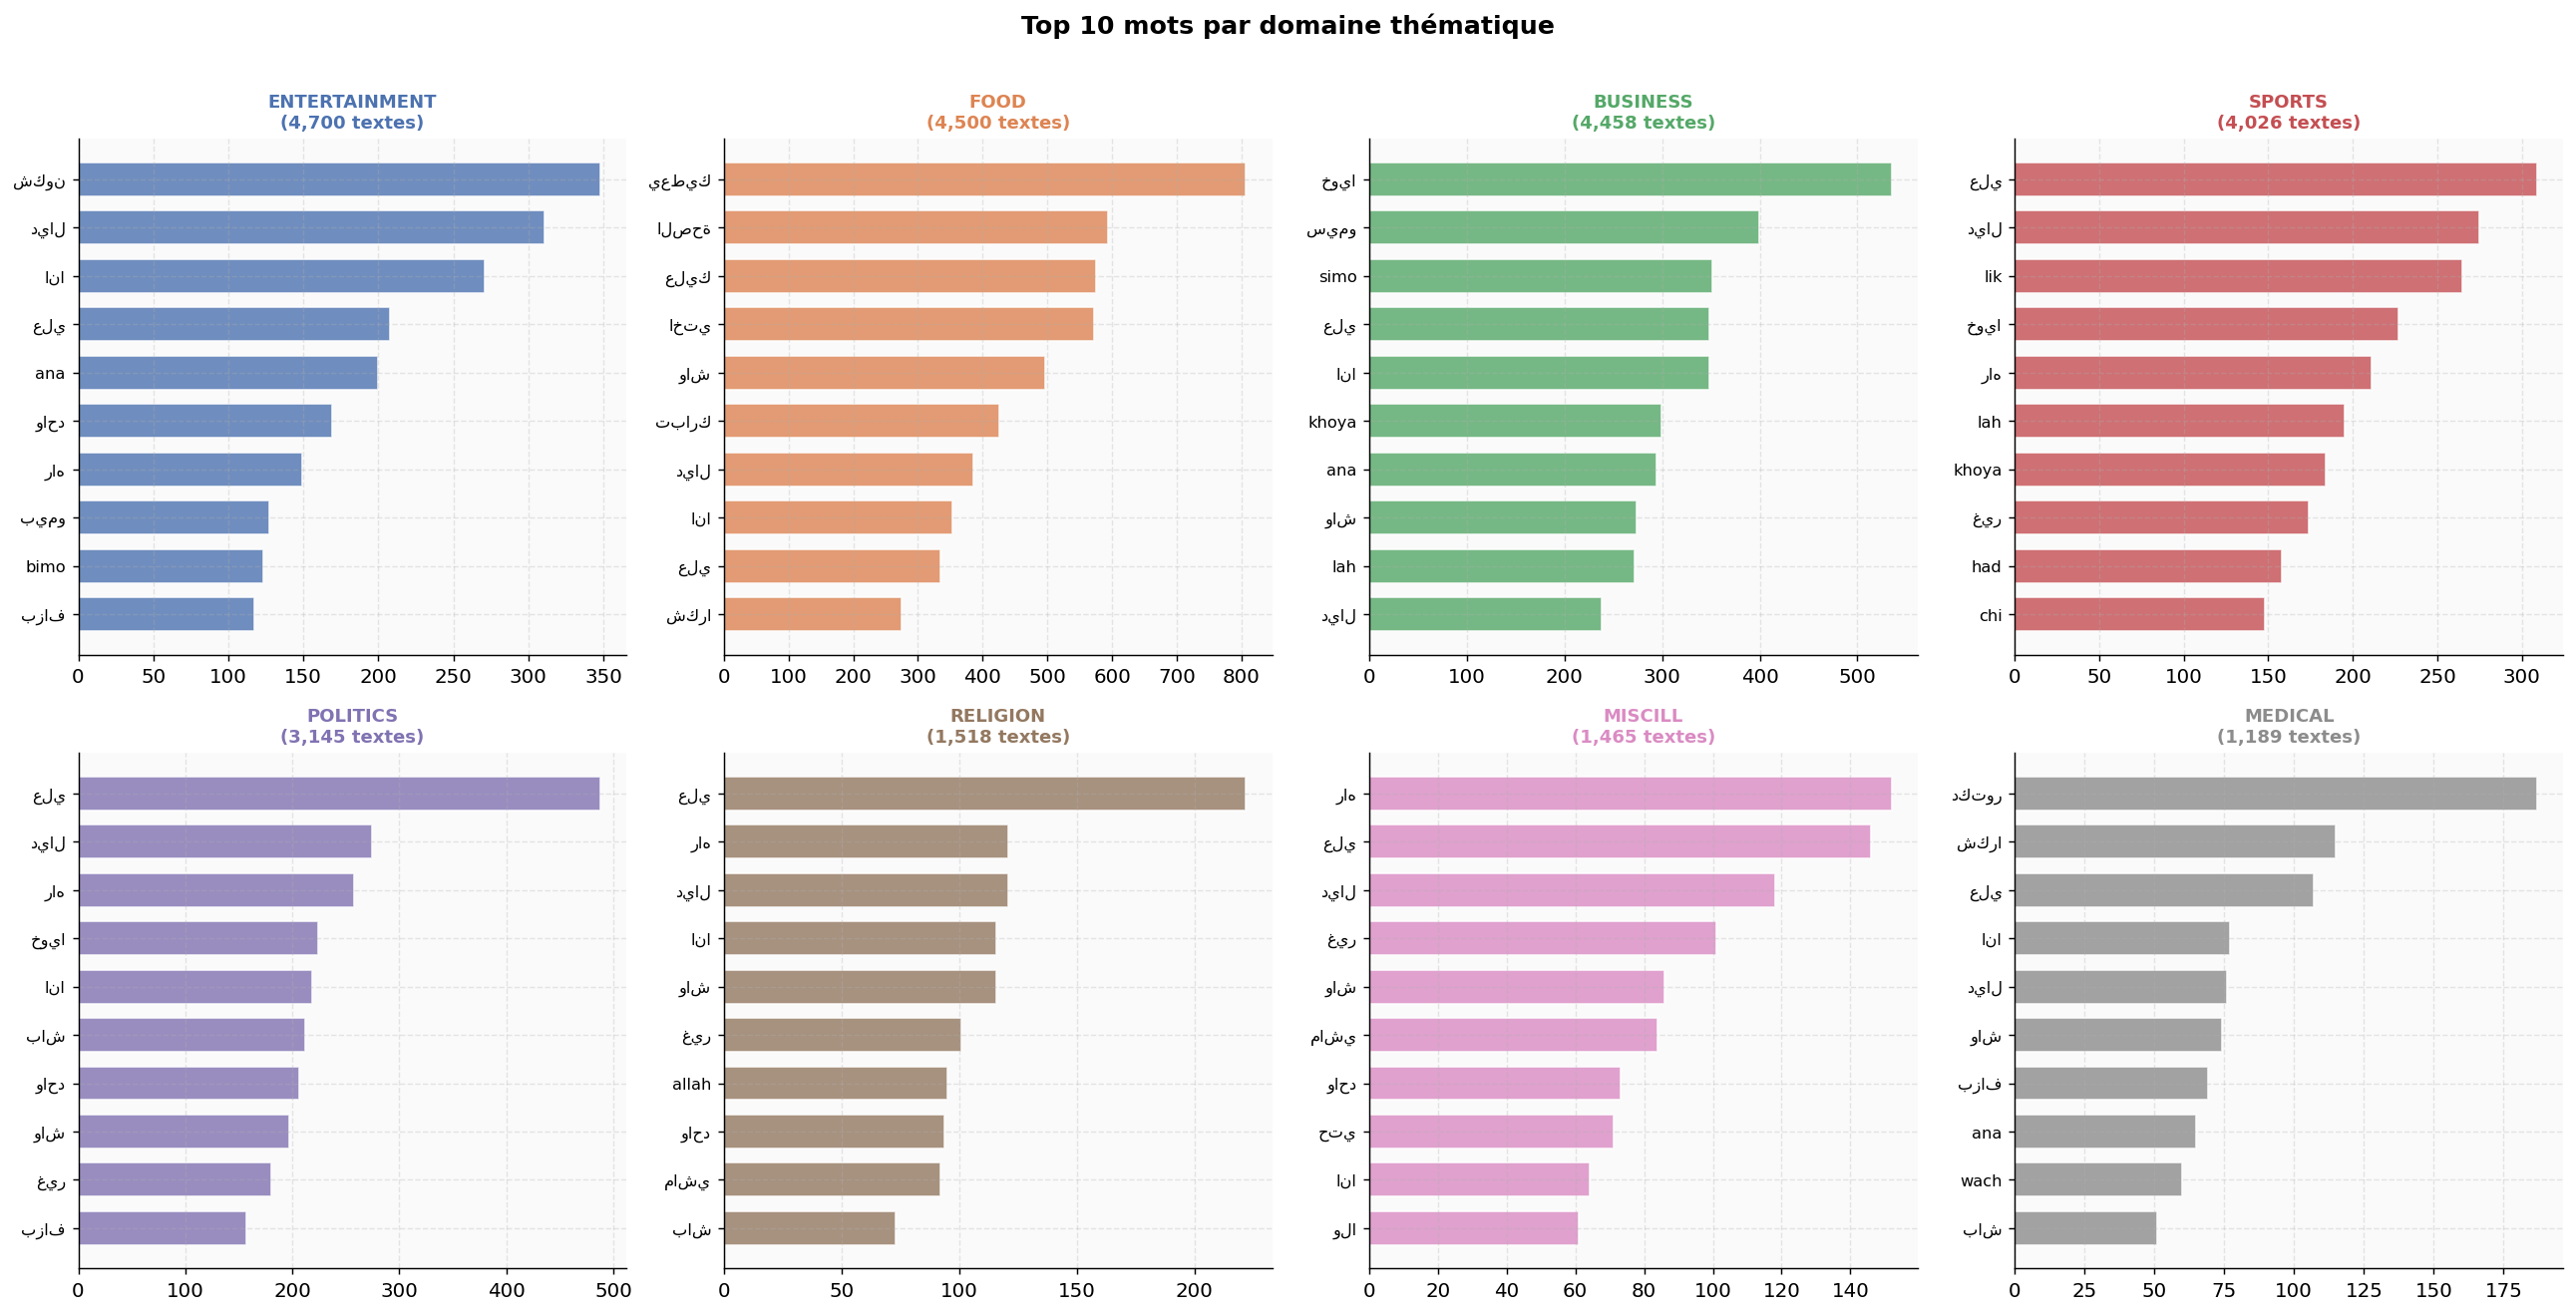

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

domains_ordered = df['domain'].value_counts().index.tolist()

for ax, domain in zip(axes, domains_ordered):
    subset = df[df['domain'] == domain]['text_normalized']
    # Mots arabes
    wc_ar = get_words(subset, arabic=True)
    wc_la = get_words(subset, arabic=False)
    wc_ar = Counter({w: c for w, c in wc_ar.items() if w not in AR_STOP and len(w) > 2})
    wc_la = Counter({w: c for w, c in wc_la.items() if w not in LAT_STOP and len(w) > 2})
    combined = wc_ar + wc_la
    
    top10 = combined.most_common(10)
    if not top10:
        continue
    words_list, counts_list = zip(*top10)
    color = PALETTE_DOMAIN.get(domain, '#999')
    bars = ax.barh(range(len(words_list)), list(counts_list)[::-1],
                   color=color, alpha=0.8, edgecolor='white', height=0.7)
    ax.set_yticks(range(len(words_list)))
    ax.set_yticklabels(list(words_list[::-1]), fontsize=9)
    n = len(subset)
    ax.set_title(f'{domain.upper()}\n({n:,} textes)', fontweight='bold', fontsize=10,
                 color=PALETTE_DOMAIN.get(domain, '#333'))

plt.suptitle('Top 10 mots par domaine thématique', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('11_mots_par_domaine')
plt.show()

---
## Section 10 — Corrélations et Relations entre Variables

### 10.1 Matrice de corrélation

La matrice de corrélation mesure les relations linéaires entre toutes les variables numériques du dataset. Une forte corrélation entre deux features peut indiquer de la redondance (et suggérer de n'en garder qu'une), ou une relation causale intéressante (ex : la longueur du texte corrèle-t-elle avec le score Darija ?).

**But :** Identifier les relations entre variables numériques pour guider la sélection de features lors de la modélisation.

  ✓ Exporté → data\reports\12_correlations.png


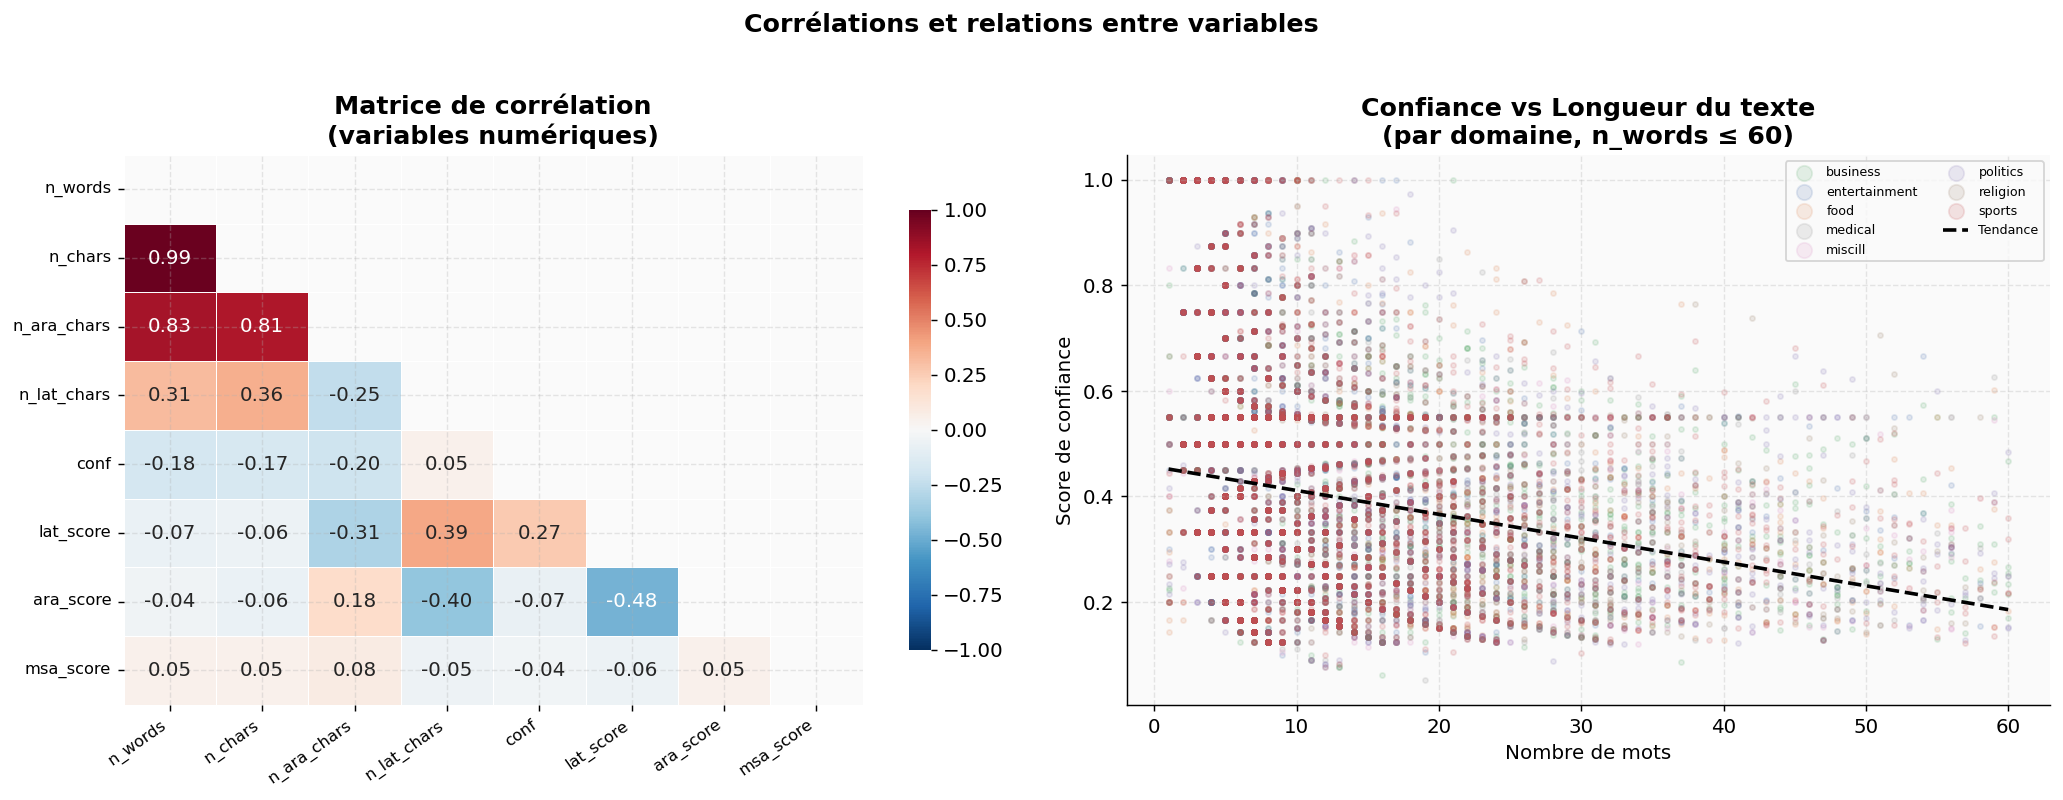

Corrélations les plus fortes (|r| > 0.5) :
  n_words ↔ n_chars : r = 0.989
  n_words ↔ n_arabic_chars : r = 0.830
  n_chars ↔ n_arabic_chars : r = 0.812


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Matrice de corrélation ────────────────────────────────────────────
num_cols = ['n_words','n_chars','n_arabic_chars','n_latin_chars',
            'det_confidence','darija_lat_score','darija_ara_score','msa_score']
corr_matrix = df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=axes[0],
            cbar_kws={'shrink': 0.8})
axes[0].set_title('Matrice de corrélation\n(variables numériques)', fontweight='bold')
col_labels = ['n_words','n_chars','n_ara_chars','n_lat_chars',
              'conf','lat_score','ara_score','msa_score']
axes[0].set_xticklabels(col_labels, rotation=35, ha='right', fontsize=9)
axes[0].set_yticklabels(col_labels, fontsize=9)

# ── n_words vs det_confidence par domaine ─────────────────────────────
for domain, grp in df[df['n_words'] <= 60].groupby('domain'):
    axes[1].scatter(grp['n_words'], grp['det_confidence'],
                    alpha=0.15, s=8, color=PALETTE_DOMAIN.get(domain,'#999'),
                    label=domain)
# Ligne de tendance globale
from numpy.polynomial.polynomial import polyfit
x_data = df[df['n_words'] <= 60]['n_words'].values
y_data = df[df['n_words'] <= 60]['det_confidence'].values
coefs = polyfit(x_data, y_data, 1)
x_range = np.linspace(1, 60, 100)
axes[1].plot(x_range, coefs[0] + coefs[1]*x_range,
             color='black', linewidth=2, linestyle='--', label='Tendance')
axes[1].set_xlabel('Nombre de mots')
axes[1].set_ylabel('Score de confiance')
axes[1].set_title('Confiance vs Longueur du texte\n(par domaine, n_words ≤ 60)')
axes[1].legend(fontsize=7, markerscale=3, ncol=2)

plt.suptitle('Corrélations et relations entre variables', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig('12_correlations')
plt.show()

# Afficher les corrélations les plus fortes
print('Corrélations les plus fortes (|r| > 0.5) :')
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i,j]
        if abs(r) > 0.5:
            print(f'  {corr_matrix.columns[i]} ↔ {corr_matrix.columns[j]} : r = {r:.3f}')

### 10.2 Profil linguistique par domaine

Ce graphique radar (toile d'araignée) synthétise en une seule visualisation le profil linguistique moyen de chaque domaine selon 5 dimensions. Il permet de comparer visuellement les domaines et de voir lesquels ont des caractéristiques similaires ou distinctes.

**But :** Avoir une vue d'ensemble des profils linguistiques pour anticiper les difficultés de classification.

  ✓ Exporté → data\reports\13_profils_radar.png


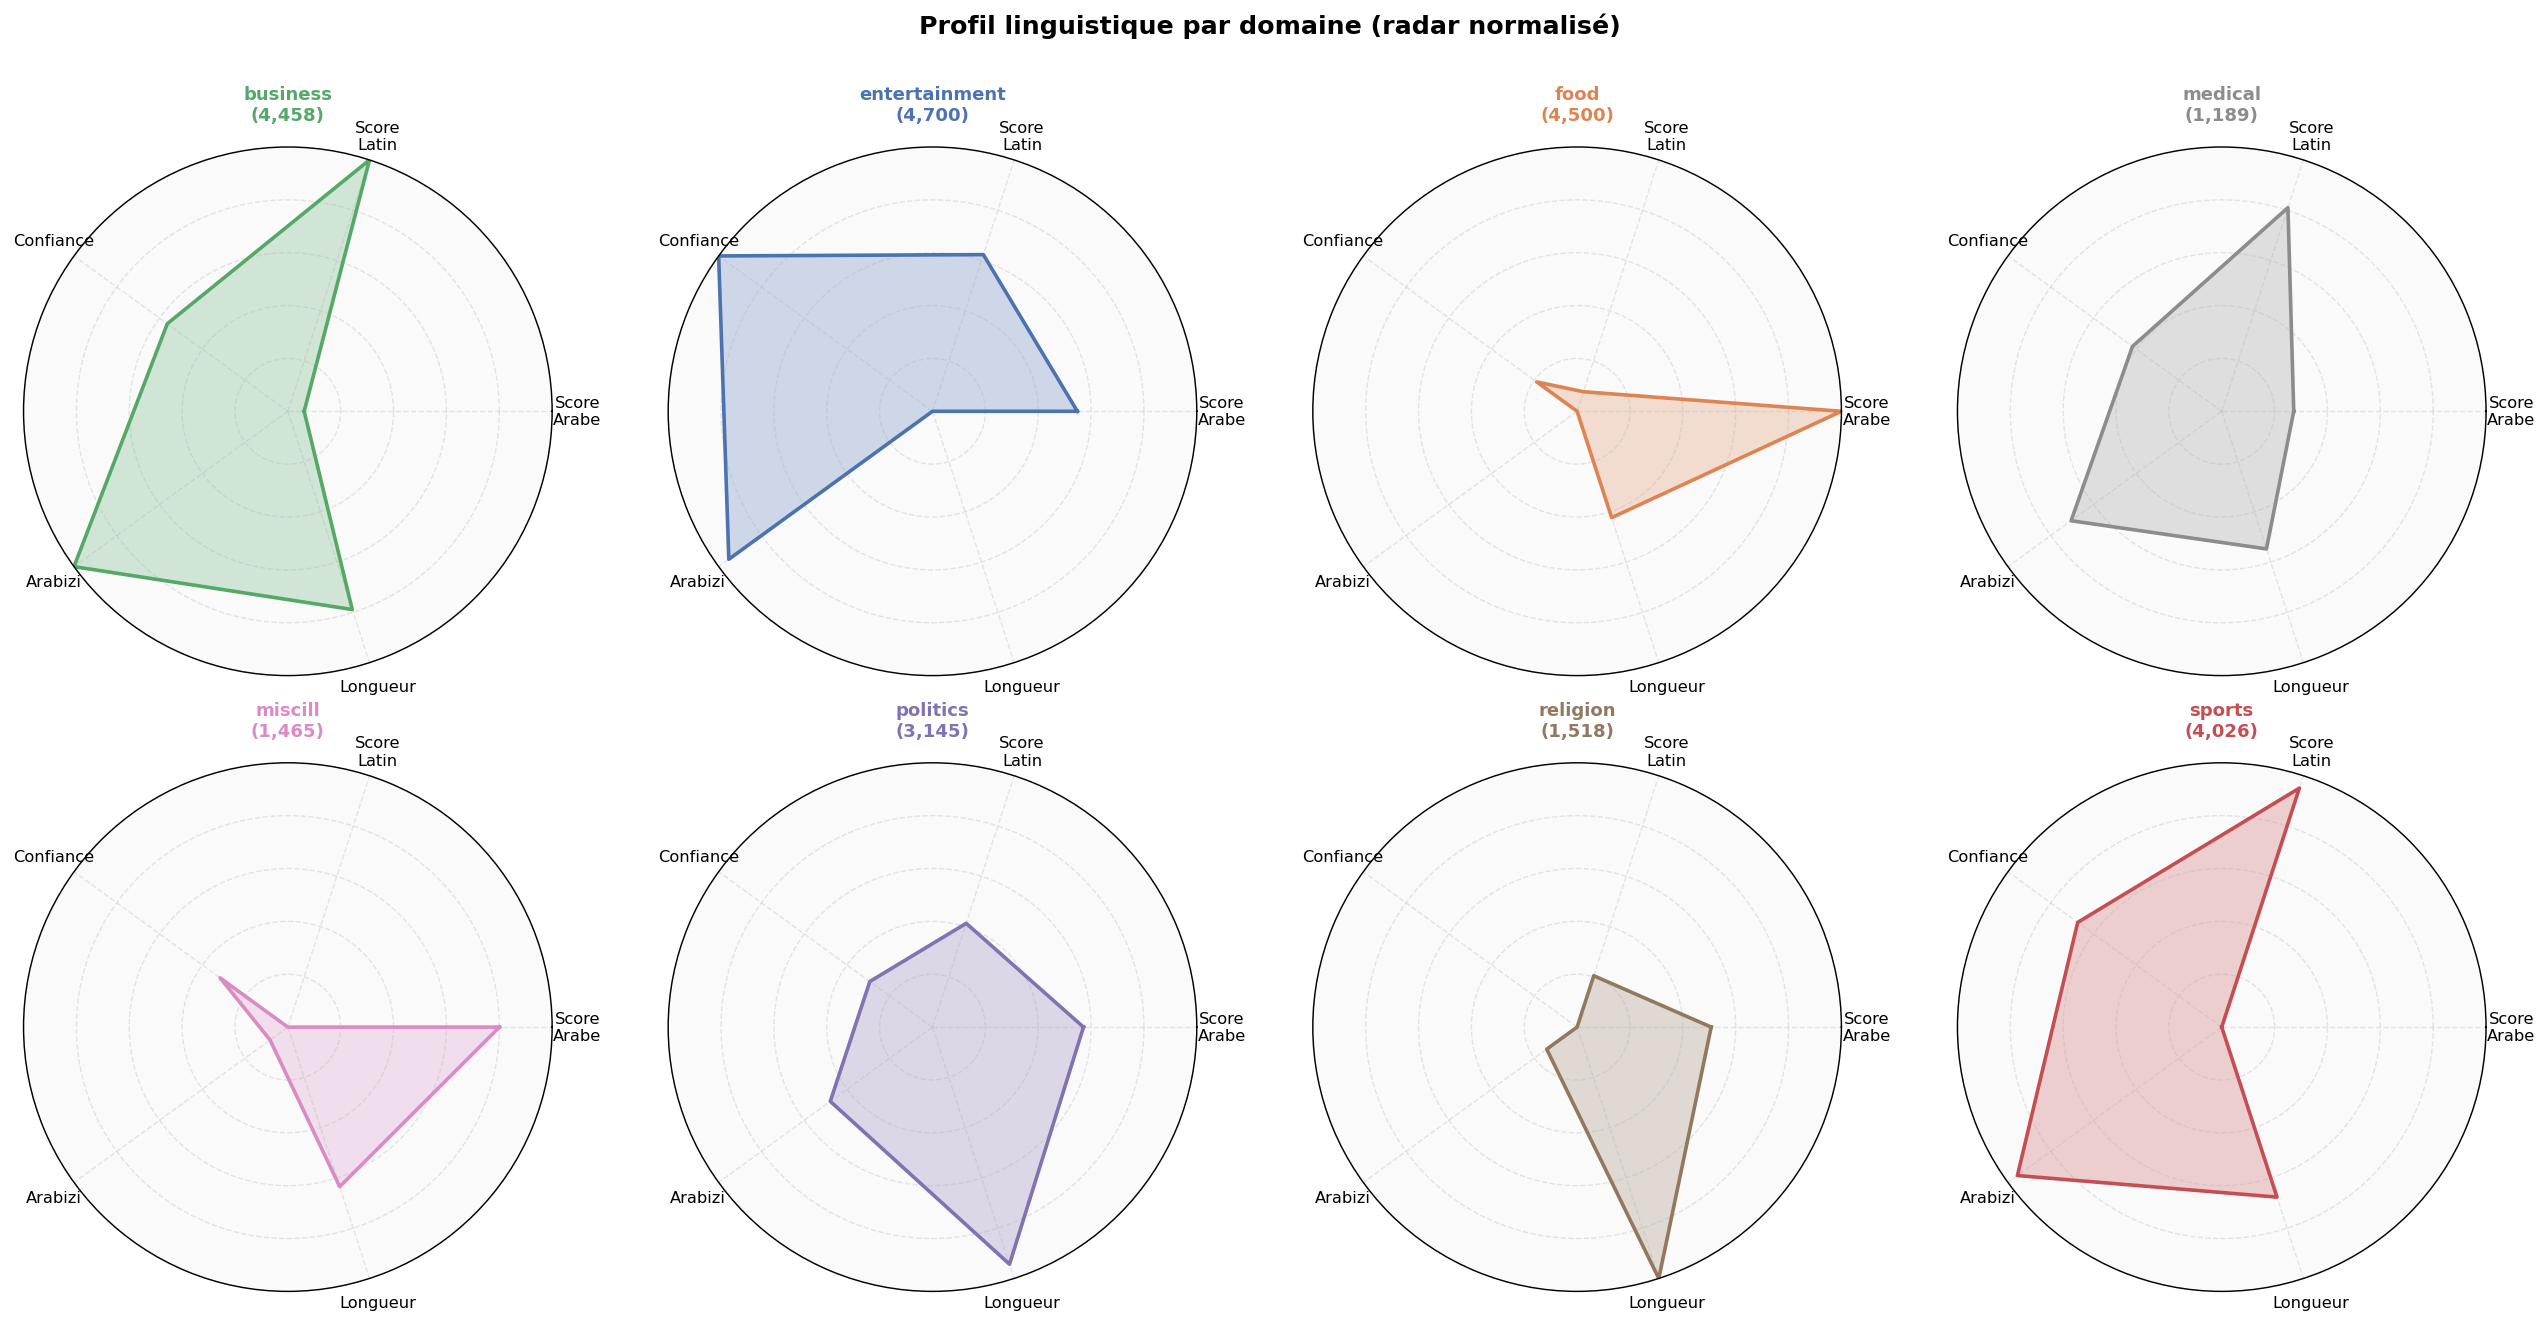

In [25]:
from matplotlib.patches import FancyArrowPatch

# Calcul des profils normalisés
profile_features = ['darija_ara_score','darija_lat_score','det_confidence',
                    'has_arabizi','n_words']
profile_labels   = ['Score\nArabe','Score\nLatin','Confiance',
                    'Arabizi','Longueur']

profiles = df.groupby('domain')[profile_features].mean()
# Normalisation 0-1 par colonne
profiles_norm = (profiles - profiles.min()) / (profiles.max() - profiles.min() + 1e-9)

N = len(profile_labels)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(2, 4, figsize=(20, 10), subplot_kw=dict(polar=True))
axes = axes.flatten()

for ax, (domain, row) in zip(axes, profiles_norm.iterrows()):
    values = row.values.flatten().tolist() + [row.values[0]]
    ax.plot(angles, values, color=PALETTE_DOMAIN.get(domain,'#999'),
            linewidth=2, linestyle='solid')
    ax.fill(angles, values, color=PALETTE_DOMAIN.get(domain,'#999'), alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(profile_labels, fontsize=9)
    ax.set_yticklabels([])
    ax.set_ylim(0, 1)
    n = len(df[df['domain']==domain])
    ax.set_title(f'{domain}\n({n:,})', fontweight='bold', fontsize=10, pad=15,
                 color=PALETTE_DOMAIN.get(domain,'#333'))
    ax.grid(True, alpha=0.3)

plt.suptitle('Profil linguistique par domaine (radar normalisé)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('13_profils_radar')
plt.show()

---
## Section 11 — Rapport de Synthèse

### 11.1 Tableau de bord final

Cette dernière section génère un tableau de bord récapitulatif de toutes les statistiques clés du dataset, exporté en JSON pour les archives du projet. Ce rapport sera utilisé comme référence dans le rapport PFE et permettra de comparer facilement ce dataset avec de futurs datasets.

**But :** Produire un document de référence synthétisant toutes les caractéristiques du dataset nettoyé.

In [26]:
# ── Statistiques globales ─────────────────────────────────────────────
print()
print('╔' + '═'*56 + '╗')
print('║         RAPPORT EDA — DATASET DARIJA 25K              ║')
print('╠' + '═'*56 + '╣')
print(f'║  Total textes          : {len(df):>8,}                    ║')
print(f'║  Chaînes uniques       : {df["channel_name"].nunique():>8}                    ║')
print(f'║  Domaines              : {df["domain"].nunique():>8}                    ║')
print(f'║  Période               : {df["date"].min().strftime("%Y")} → {df["date"].max().strftime("%Y")}                   ║')
print('╠' + '═'*56 + '╣')
print('║  TYPES DE DARIJA                                       ║')
for t, n in df['darija_type'].value_counts().items():
    print(f'║    {t:<25} : {n:>6,}  ({n/len(df)*100:.1f}%)     ║')
print('╠' + '═'*56 + '╣')
print('║  LONGUEURS TEXTES                                      ║')
print(f'║    Moyenne mots         : {df["n_words"].mean():>7.1f}                     ║')
print(f'║    Médiane mots         : {df["n_words"].median():>7.0f}                     ║')
print(f'║    Textes ≤ 5 mots      : {(df["n_words"]<=5).sum():>7,}  ({(df["n_words"]<=5).mean()*100:.1f}%)     ║')
print(f'║    Textes > 50 mots     : {(df["n_words"]>50).sum():>7,}  ({(df["n_words"]>50).mean()*100:.1f}%)      ║')
print('╠' + '═'*56 + '╣')
print('║  LINGUISTIQUE                                          ║')
print(f'║    Script arabe         : {(df["script"]=="arabic").sum():>7,}  ({(df["script"]=="arabic").mean()*100:.1f}%)    ║')
print(f'║    Script latin         : {(df["script"]=="latin").sum():>7,}  ({(df["script"]=="latin").mean()*100:.1f}%)    ║')
print(f'║    Script mixte         : {(df["script"]=="mixed").sum():>7,}  ({(df["script"]=="mixed").mean()*100:.1f}%)      ║')
print(f'║    Avec Arabizi         : {df["has_arabizi"].sum():>7,}  ({df["has_arabizi"].mean()*100:.1f}%)    ║')
print(f'║    Code-switching       : {df["has_codeswitching"].sum():>7,}   ({df["has_codeswitching"].mean()*100:.1f}%)      ║')
print('╠' + '═'*56 + '╣')
print(f'║  Confiance moy détecteur: {df["det_confidence"].mean():>7.3f}                     ║')
print(f'║  Conf < 0.2 (ambigus)   : {(df["det_confidence"]<0.2).sum():>7,}  ({(df["det_confidence"]<0.2).mean()*100:.1f}%)      ║')
print('╚' + '═'*56 + '╝')


╔════════════════════════════════════════════════════════╗
║         RAPPORT EDA — DATASET DARIJA 25K              ║
╠════════════════════════════════════════════════════════╣
║  Total textes          :   25,001                    ║
║  Chaînes uniques       :       32                    ║
║  Domaines              :        8                    ║
║  Période               : 2015 → 2026                   ║
╠════════════════════════════════════════════════════════╣
║  TYPES DE DARIJA                                       ║
║    darija_arabic             : 15,517  (62.1%)     ║
║    darija_latin              :  9,276  (37.1%)     ║
║    darija_mixed              :    208  (0.8%)     ║
╠════════════════════════════════════════════════════════╣
║  LONGUEURS TEXTES                                      ║
║    Moyenne mots         :    12.8                     ║
║    Médiane mots         :       8                     ║
║    Textes ≤ 5 mots      :   6,887  (27.5%)     ║
║    Textes > 50 mots     

In [27]:
# ── Export JSON du rapport ────────────────────────────────────────────
report = {
    "meta": {
        "fichier": "dataset_25k_cleaned.csv",
        "date_eda": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "total_textes": int(len(df)),
        "periode": {
            "debut": df["date"].min().strftime("%Y-%m-%d"),
            "fin":   df["date"].max().strftime("%Y-%m-%d"),
        }
    },
    "distribution_domaines": df['domain'].value_counts().to_dict(),
    "distribution_types":    df['darija_type'].value_counts().to_dict(),
    "distribution_scripts":  df['script'].value_counts().to_dict(),
    "statistiques_longueur": df['n_words'].describe().round(2).to_dict(),
    "statistiques_confiance": df['det_confidence'].describe().round(4).to_dict(),
    "linguistique": {
        "pct_arabizi":       round(df['has_arabizi'].mean()*100, 2),
        "pct_codeswitching": round(df['has_codeswitching'].mean()*100, 2),
        "pct_textes_courts": round((df['n_words']<=5).mean()*100, 2),
        "pct_textes_longs":  round((df['n_words']>50).mean()*100, 2),
    },
    "top5_chaines": df['channel_name'].value_counts().head(5).to_dict(),
    "scores_moyens_par_domaine": df.groupby('domain')[
        ['darija_lat_score','darija_ara_score','msa_score','det_confidence']
    ].mean().round(4).to_dict(),
}

report_path = REPORT_DIR / 'eda_report.json'
report_path.write_text(
    json.dumps(report, ensure_ascii=False, indent=2),
    encoding='utf-8'
)
print(f'✓ Rapport JSON exporté → {report_path}')
print()
print('── Fichiers exportés dans data/reports/ ──')
for f in sorted(REPORT_DIR.glob('*')):
    print(f'  {f.name}')

✓ Rapport JSON exporté → data\reports\eda_report.json

── Fichiers exportés dans data/reports/ ──
  01_distribution_domaines.png
  02_desequilibre_classes.png
  03_types_darija.png
  04_confiance_detecteur.png
  05_longueurs_textes.png
  06_analyse_temporelle.png
  07_analyse_chaines.png
  08_analyse_linguistique.png
  09_scores_detecteur.png
  10_mots_frequents_types.png
  11_mots_par_domaine.png
  12_correlations.png
  13_profils_radar.png
  eda_report.json


---
## Conclusions de l'EDA

### Points clés identifiés

**1. Déséquilibre fort des classes**  
Le domaine `entertainment` représente 53.2% du dataset contre seulement 1.7% pour `medical`. Ce déséquilibre nécessitera des techniques d'équilibrage lors de l'entraînement.

**2. Prédominance du Darija arabe**  
64.2% des textes sont en Darija arabe, 35.0% en Darija latin et 0.8% mixte. Les modèles multilingues ou des embeddings spécialisés seront nécessaires pour couvrir les deux scripts.

**3. Forte présence de l'Arabizi**  
32.8% des textes contiennent des chiffres phonétiques (3, 7, 9...), particulièrement dans les domaines business (44.1%) et sports (42.7%). Le tokeniseur devra gérer ce phénomène.

**4. Textes généralement courts**  
67.1% des textes ont moins de 10 mots. Cette brièveté limite le contexte disponible pour la classification et favorise les modèles capables de traiter des micro-textes.

**5. Label = thème chaîne ≠ thème commentaire**  
Les labels actuels reflètent le thème de la chaîne scrapée et non le vrai thème du commentaire. Une annotation LLM est indispensable avant l'entraînement.

### Prochaines étapes

1. **Annotation semi-automatique** via Claude API (batches de 20 textes)
2. **Validation humaine** sur 300 échantillons (Cohen's κ ≥ 0.7)
3. **Entraînement du classifieur** avec suivi MLflow/W&B